In [394]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic

#### Importing Files

In [395]:
def lowerColName(df):
    df.columns = [i.lower() for i in df.columns]
    return df.columns

customers = pd.read_csv('datasets/customers.csv')
customers.columns = lowerColName(customers)

sales = pd.read_csv('datasets/sales.csv')
sales.columns = lowerColName(sales)

products = pd.read_csv('datasets/products.csv')
products.columns = lowerColName(products)

#### Understanding the files

In [396]:
customers.head()

,customer_id,customer_name,gender,age,age_group,date_of_birth,email,phone,city,state,pincode,registration_date,customer_tier,total_orders,total_spent
0,CUST00000001,Akash Agarwal,male,48,46-55,1977-01-13,akashagarwal@gmail.com,+91-9625152011,Patiala,Punjab,122521,2024-01-28,Gold,5,40098.48
1,CUST00000002,Farhan Rahman,male,73,65+,1952-01-20,farhanrahman@gmail.com,+91-8593009465,Durgapur,West Bengal,226518,2023-08-25,Platinum,8,63676.24
2,CUST00000003,Suresh Kumar,male,31,26-35,1994-01-09,sureshkumar755@gmail.com,+91-7935884774,Gurugram,Haryana,520400,2023-08-30,Silver,0,0.00
3,CUST00000004,Aditya Pandey,male,41,36-45,1984-01-12,adityapandey@outlook.com,+91-9015046072,Kolkata,West Bengal,735356,2024-03-11,Platinum,5,288324.84
4,CUST00000005,Hina Khan,female,53,46-55,1972-01-15,hinakhan433@gmail.com,+91-8813094271,Noida,UP,985141,2024-04-19,Platinum,4,69265.75


In [397]:
products.head()

,product_id,product_name,category,brand,original_price,discount_percent,discount_amount,selling_price,stock_quantity,weight_kg,avg_rating,total_reviews
0,PROD000001,Samsung Mobile V5,Electronics,Samsung,130561.34,23,30029.11,100532.23,159,2.63,4.49,102
1,PROD000002,HP Laptop V5,Electronics,HP,36494.92,34,12408.27,24086.65,54,4.19,4.32,107
2,PROD000003,boAt Headphones V2,Electronics,boAt,106587.94,42,44766.93,61821.01,638,1.48,4.31,99
3,PROD000004,Noise Watch V7,Electronics,Noise,81275.27,47,38199.38,43075.89,572,3.30,4.42,127
4,PROD000005,Apple iPhone V4,Electronics,Apple,13099.36,43,5632.72,7466.64,865,3.71,4.37,98


In [398]:
sales.head()

,order_id,customer_id,product_id,order_date,order_time,delivery_date,quantity,unit_price,order_value,shipping_cost,...,coupon_discount,total_amount,payment_mode,order_status,rating,review_text,city,state,customer_age,customer_age_group
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,2622.46,2622.46,0.0,...,0.0,2622.46,COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,90258.00,90258.00,0.0,...,0.0,90258.00,COD,Delivered,4.0,Nice quality,Durgapur,West Bengal,22,18-25
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,3536.50,3536.50,0.0,...,0.0,3536.50,UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,34081.56,34081.56,0.0,...,50.0,34031.56,Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,69021.17,138042.34,0.0,...,0.0,138042.34,UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45


In [399]:
print(sales.shape, customers.shape, products.shape)

(250000, 21) (40000, 15) (2000, 12)


#### Working on Customers Table

In [400]:
customers.describe()

,age,pincode,total_orders,total_spent
count,40000.000000,40000.000000,40000.000000,40000.00000
mean,35.306225,549135.098375,5.003475,118539.15886
std,12.581443,259430.688860,2.232485,106205.42346
min,18.000000,100010.000000,0.000000,0.00000
25%,26.000000,325689.750000,3.000000,37814.14750
50%,33.000000,547573.500000,5.000000,90059.66000
75%,43.000000,773876.000000,6.000000,169958.41750
max,75.000000,999986.000000,17.000000,890131.55000


In [401]:
customers.isnull().sum()

customer_id          0
customer_name        0
gender               0
age                  0
age_group            0
date_of_birth        0
email                0
phone                0
city                 0
state                0
pincode              0
registration_date    0
customer_tier        0
total_orders         0
total_spent          0
dtype: int64

In [402]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        40000 non-null  str    
 1   customer_name      40000 non-null  str    
 2   gender             40000 non-null  str    
 3   age                40000 non-null  int64  
 4   age_group          40000 non-null  str    
 5   date_of_birth      40000 non-null  str    
 6   email              40000 non-null  str    
 7   phone              40000 non-null  str    
 8   city               40000 non-null  str    
 9   state              40000 non-null  str    
 10  pincode            40000 non-null  int64  
 11  registration_date  40000 non-null  str    
 12  customer_tier      40000 non-null  str    
 13  total_orders       40000 non-null  int64  
 14  total_spent        40000 non-null  float64
dtypes: float64(1), int64(3), str(11)
memory usage: 8.8 MB


* Making the decision to drop columns - age_group, date_of_birth, phone
* Change the datatype of column age to int8/int16, and total_orders to int8

In [403]:
customers.drop(columns=['age_group','date_of_birth','phone'], inplace=True)

In [404]:
customers.age = customers.age.astype(np.int8)
customers.total_orders = customers.total_orders.astype(np.int8)

#### Working with Sales Table

In [405]:
sales.describe()

,quantity,unit_price,order_value,shipping_cost,coupon_discount,total_amount,rating,customer_age
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,120030.000000,250000.000000
mean,1.249580,19202.477645,23967.862192,4.911971,250.001146,23722.773017,4.399400,35.309416
std,0.535689,26720.495176,37629.320529,18.141581,1399.928532,37267.644163,0.663915,12.574524
min,1.000000,26.130000,26.130000,0.000000,0.000000,-21.560000,3.000000,18.000000
25%,1.000000,1551.550000,1825.890000,0.000000,0.000000,1803.900000,4.000000,26.000000
50%,1.000000,7208.930000,8411.160000,0.000000,0.000000,8339.490000,4.000000,33.000000
75%,1.000000,24433.270000,28612.810000,0.000000,0.000000,28344.920000,5.000000,43.000000
max,3.000000,136973.330000,410919.990000,90.000000,41092.000000,410919.990000,5.000000,75.000000


In [406]:
sales.isnull().sum().sort_values(ascending=False)

coupon_code           199815
review_text           129970
rating                129970
customer_id                0
order_id                   0
order_time                 0
order_date                 0
product_id                 0
delivery_date              0
order_value                0
shipping_cost              0
unit_price                 0
quantity                   0
total_amount               0
coupon_discount            0
order_status               0
payment_mode               0
city                       0
state                      0
customer_age               0
customer_age_group         0
dtype: int64

* Handling Null Values
    - coupon code: NotApplicable
    - review text: NotProvided
    - rating: Replacing with the average of all ratings

In [407]:
sales.coupon_code = sales.coupon_code.fillna("NOT APPLICABLE")
sales.review_text = sales.review_text.fillna("NOT APPLICABLE")

avgRating = sales.rating.dropna().mean()
sales.rating = sales.rating.fillna(avgRating)

In [408]:
sales.rating.mean()

np.float64(4.39940014996251)

In [409]:
sales.rating.unique()

array([4.39940015, 4.        , 5.        , 3.        ])

In [410]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            250000 non-null  str    
 1   customer_id         250000 non-null  str    
 2   product_id          250000 non-null  str    
 3   order_date          250000 non-null  str    
 4   order_time          250000 non-null  str    
 5   delivery_date       250000 non-null  str    
 6   quantity            250000 non-null  int64  
 7   unit_price          250000 non-null  float64
 8   order_value         250000 non-null  float64
 9   shipping_cost       250000 non-null  float64
 10  coupon_code         250000 non-null  str    
 11  coupon_discount     250000 non-null  float64
 12  total_amount        250000 non-null  float64
 13  payment_mode        250000 non-null  str    
 14  order_status        250000 non-null  str    
 15  rating              250000 non-null  float64


* Change the datatype of quantity to int8 and rating to int8
* Dropping the columns - city, state, customer_age, customer_age_group - because they are already present in the customers table

In [411]:
sales.drop(columns=['city','state','customer_age','customer_age_group'], inplace=True)

In [412]:
sales.quantity = sales.quantity.astype(np.int8)
sales.rating = sales.rating.astype(np.float16)

#### Working with products table

In [413]:
products.describe()

,original_price,discount_percent,discount_amount,selling_price,stock_quantity,weight_kg,avg_rating,total_reviews
count,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000
mean,18323.619210,27.471000,5143.28014,13180.33907,503.479000,2.640980,4.398185,60.015000
std,29472.155725,13.309874,9732.99126,21514.94963,287.140337,1.373574,0.095983,27.645161
min,52.250000,5.000000,6.29000,26.13000,10.000000,0.210000,3.910000,15.000000
25%,1522.505000,16.000000,332.26000,1088.03750,250.750000,1.430000,4.340000,38.000000
50%,4775.355000,27.000000,1154.91500,3543.41500,504.500000,2.725000,4.400000,54.000000
75%,22358.115000,39.000000,5452.93500,16063.81250,749.000000,3.790000,4.460000,78.000000
max,149658.640000,50.000000,71289.60000,136973.33000,1000.000000,5.000000,4.760000,139.000000


In [414]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        2000 non-null   str    
 1   product_name      2000 non-null   str    
 2   category          2000 non-null   str    
 3   brand             2000 non-null   str    
 4   original_price    2000 non-null   float64
 5   discount_percent  2000 non-null   int64  
 6   discount_amount   2000 non-null   float64
 7   selling_price     2000 non-null   float64
 8   stock_quantity    2000 non-null   int64  
 9   weight_kg         2000 non-null   float64
 10  avg_rating        2000 non-null   float64
 11  total_reviews     2000 non-null   int64  
dtypes: float64(5), int64(3), str(4)
memory usage: 261.2 KB


* Change the Datatype of column avg_ratings to float16 and total_reviews to int16 and weight_kg to float16 and stock_quantity to int32

In [415]:
products.avg_rating = products.avg_rating.astype(np.float16)
products.total_reviews = products.total_reviews.astype(np.int16)
products.weight_kg = products.weight_kg.astype(np.float16)
products.stock_quantity = products.stock_quantity.astype(np.int32)

In [416]:
products.isnull().sum()

product_id          0
product_name        0
category            0
brand               0
original_price      0
discount_percent    0
discount_amount     0
selling_price       0
stock_quantity      0
weight_kg           0
avg_rating          0
total_reviews       0
dtype: int64

# UNIVARIATE ANALYSIS on CUSTOMER table

### Summary of univariate analysis of the customer table

    - Platinum Members Dominate with strength of around 2/3rd
    - Males and Females are EQUALLY present
    - Majority of the puchases are of low value items, < 100000 Rs
    - Many Customers Fall in the age group of [20-35]

In [417]:
customers.columns

Index(['customer_id', 'customer_name', 'gender', 'age', 'email', 'city',
       'state', 'pincode', 'registration_date', 'customer_tier',
       'total_orders', 'total_spent'],
      dtype='str')

Text(0.5, 1.0, 'UNIVARIATE ANALYSIS ON AGE')

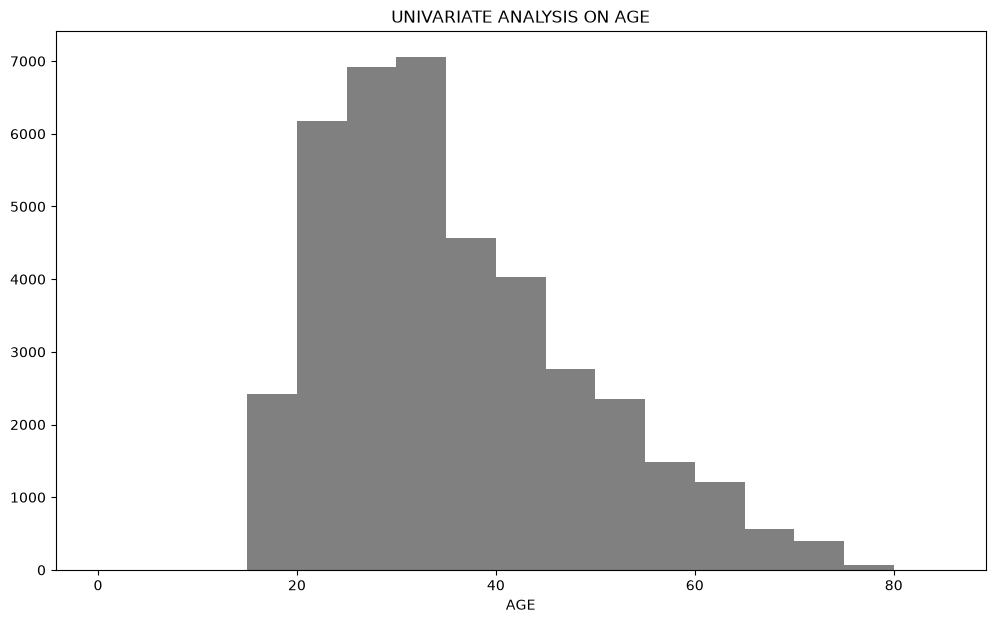

In [418]:
plt.hist(customers.age, bins=[0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85], color='grey')
plt.xlabel("AGE")
plt.title("UNIVARIATE ANALYSIS ON AGE")

<Axes: xlabel='age', ylabel='Density'>

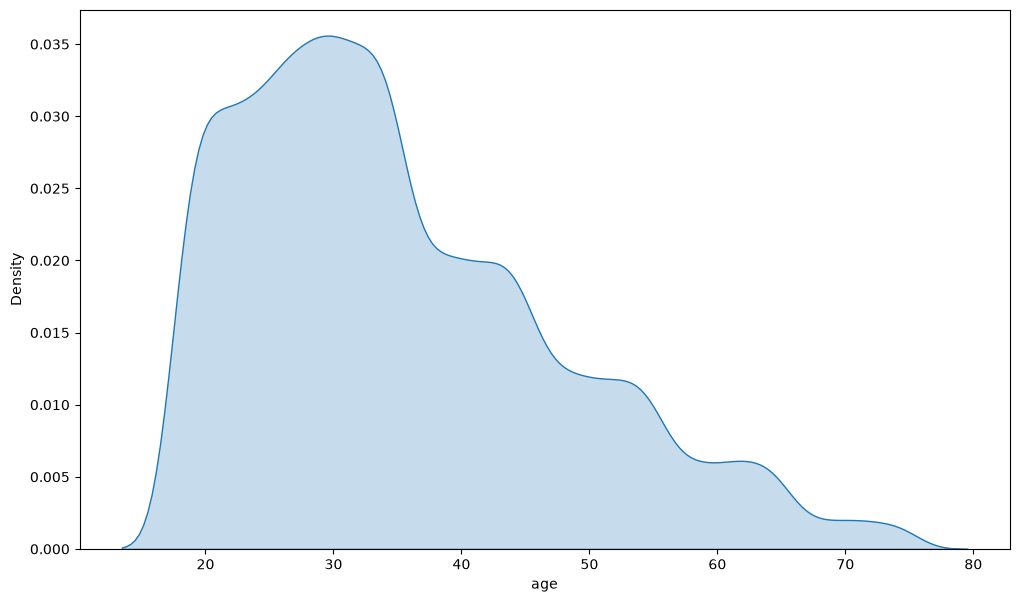

In [419]:
sns.kdeplot(customers.age, fill=True)

* Many Customers Fall in the age group of [20-35]

Text(0.5, 1.0, 'UNIVARIATE ANALYSIS ON TOTAL SPENT')

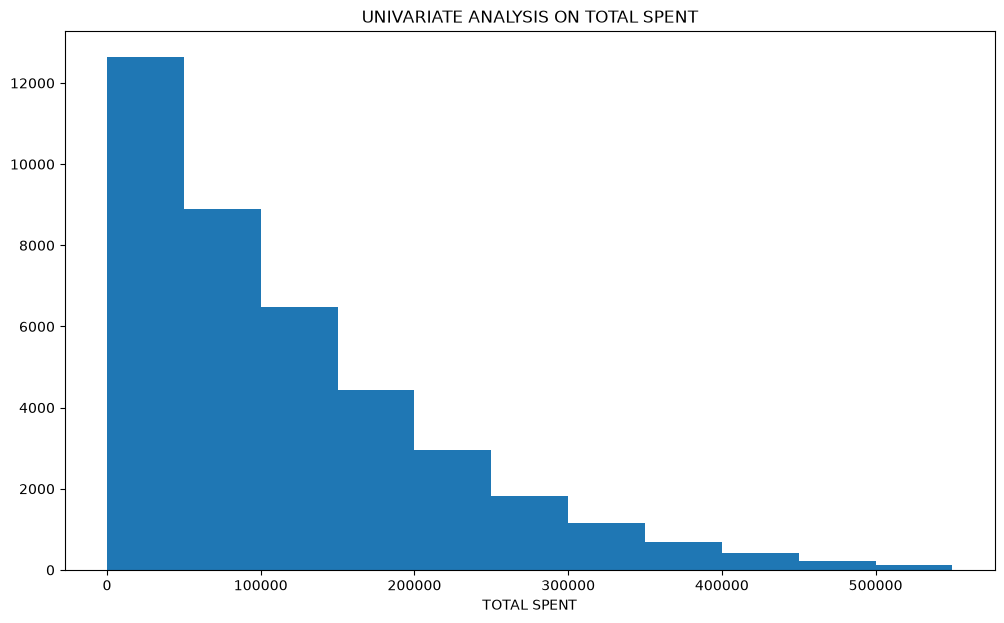

In [420]:
plt.hist(customers.total_spent, bins=[0,50000,100000,150000,200000,250000,300000,350000,400000,450000,500000,550000])
plt.xlabel("TOTAL SPENT")
plt.title("UNIVARIATE ANALYSIS ON TOTAL SPENT")

<Axes: xlabel='total_spent', ylabel='Density'>

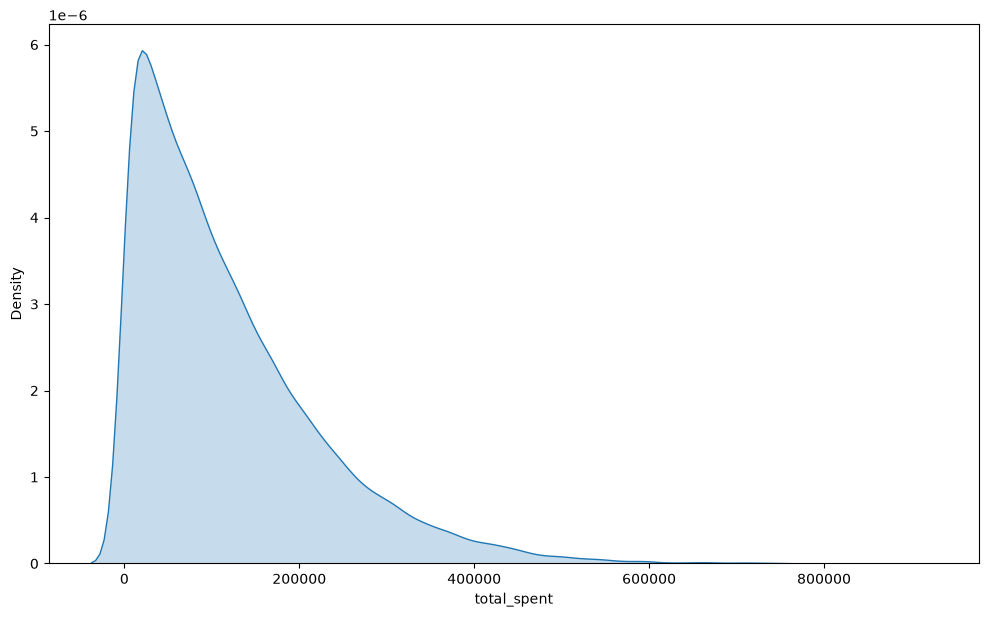

In [421]:
sns.kdeplot(customers.total_spent, fill=True)

* Majority of the puchases are of low value items, < 100000 Rs

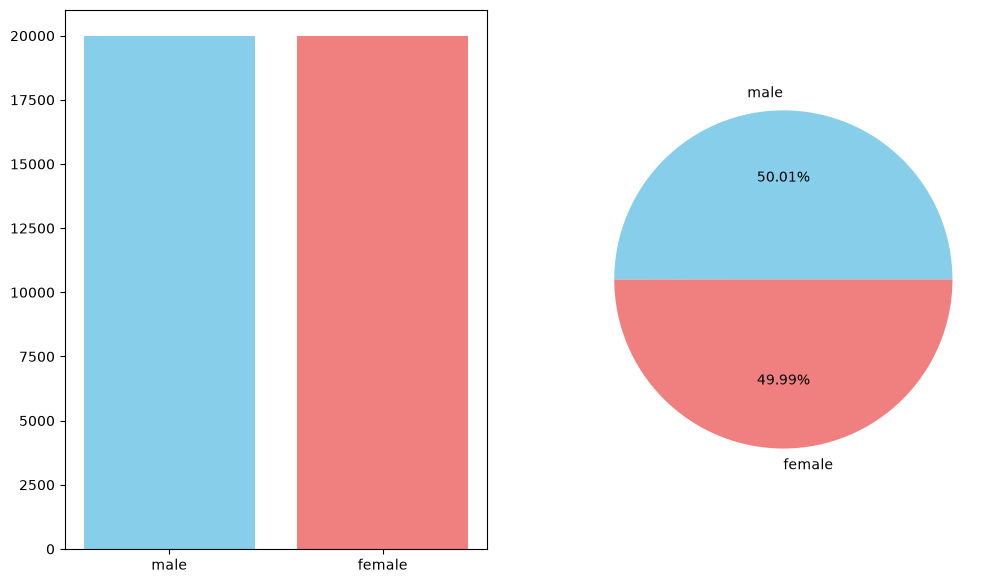

In [422]:
gender_counts = customers.gender.value_counts()

fig, ax = plt.subplots(nrows=1, ncols=2)
ax[0].bar(gender_counts.index, gender_counts.values, color=['skyblue', 'lightcoral'])
ax[1].pie(gender_counts.values, labels=gender_counts.index, colors=['skyblue', 'lightcoral'], autopct='%0.2f%%')

* Males and Females are EQUALLY present

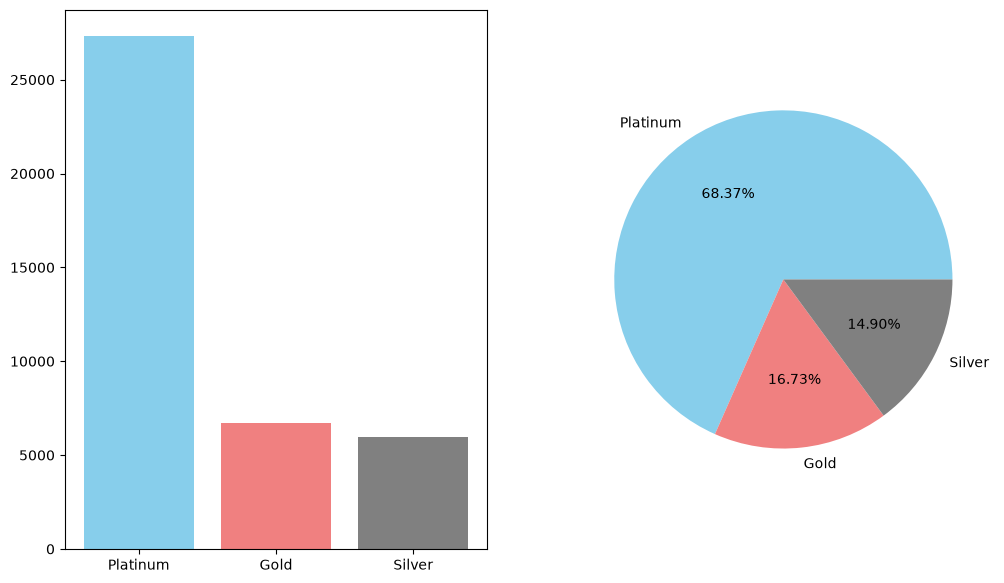

In [423]:
customer_tier_counts = customers.customer_tier.value_counts()

fig, ax = plt.subplots(nrows=1, ncols=2)
ax[0].bar(customer_tier_counts.index, customer_tier_counts.values, color=['skyblue', 'lightcoral', 'grey'])
ax[1].pie(customer_tier_counts.values, labels=customer_tier_counts.index, colors=['skyblue', 'lightcoral', 'grey'], autopct='%0.2f%%')

* Platinum Members Dominate with strength of around 2/3rd

# UNIVARIATE ANALYSIS on SALES table

### Summary of univariate analysis of the sales table

    - Majority (almost all) of the items are shipped at ZERO COST
    - Almost half (51.4%) payments are done through UPI, followed by COD (32.9%)
    - Delivery
        * 80 Percent of the orders are delivered.
        * Cancelled and Returened makes 10 percent of the orders
    - LEAST NUMBER Of Products Got NEGATIVE review
    - Month
        * Maximum Orders are recieved in the month of June.
        * Rest all months have recieved alsmost same number of orders 
    - Time
        * Uniform Hourly Demand: Order volume remains virtually constant across all 24 hours of the day, averaging ~10,400 to 10,600 orders per hour (~4.17% of daily volume per hour) with no discernible peak or off-peak hours.

(array([232459.,      0.,      0.,      0.,      0.,   1760.,   3917.,
          3955.,   3994.,   3915.]),
 array([ 0.,  9., 18., 27., 36., 45., 54., 63., 72., 81., 90.]),
 <BarContainer object of 10 artists>)

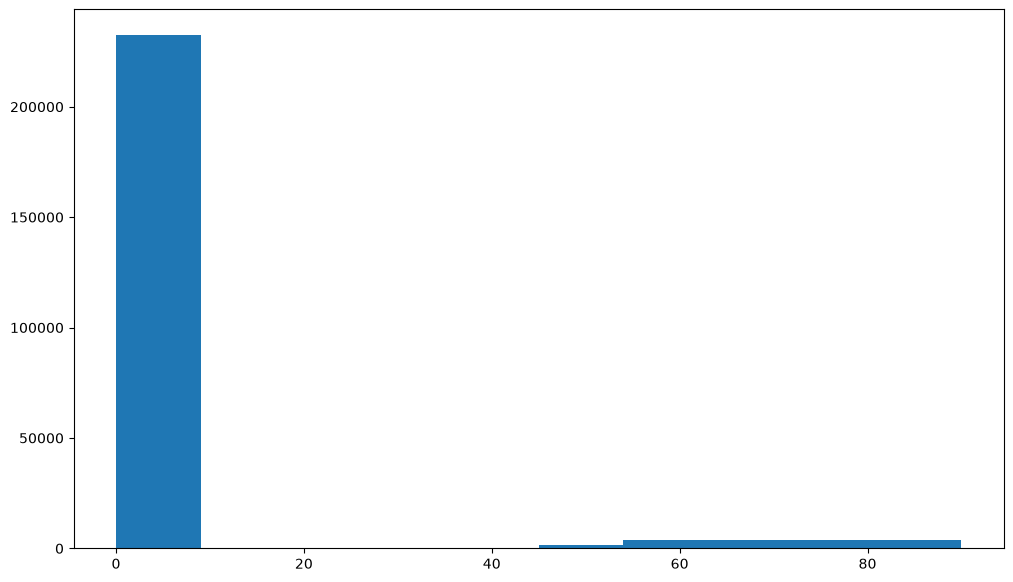

In [424]:
plt.hist(sales.shipping_cost)

<Axes: xlabel='shipping_cost', ylabel='Density'>

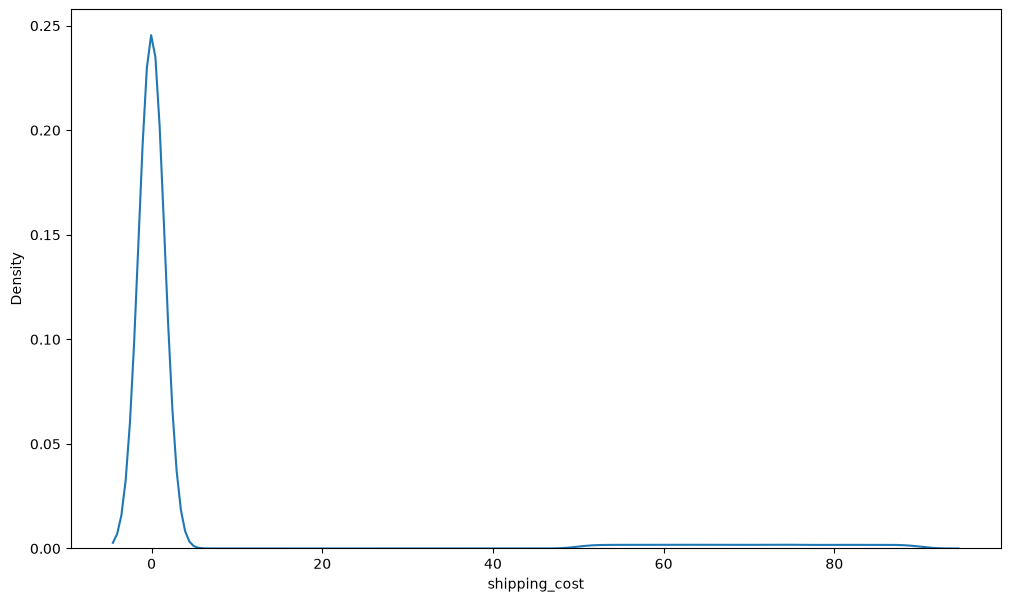

In [425]:
sns.kdeplot(sales.shipping_cost)

In [426]:
sales.shipping_cost.value_counts()

shipping_cost
0.00     232459
78.81        14
70.35        14
57.23        13
77.46        13
          ...  
58.44         1
65.31         1
65.58         1
80.42         1
68.82         1
Name: count, Length: 3938, dtype: int64

* Majority (almost all) of the items are shipped at ZERO COST

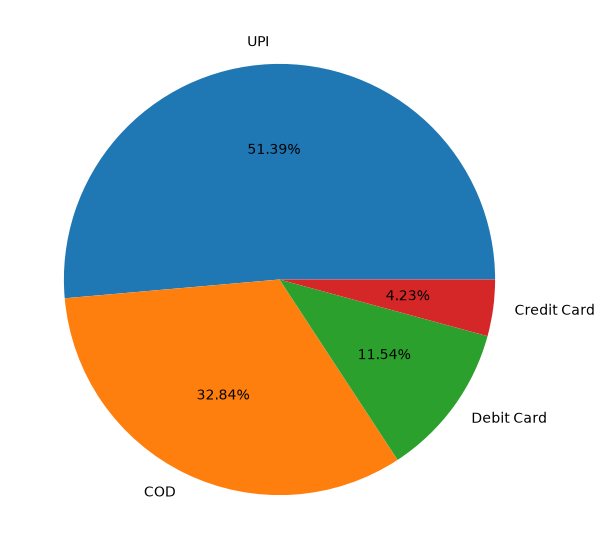

In [427]:
payment_mode_count = sales.payment_mode.value_counts()
plt.pie(payment_mode_count.values, labels=payment_mode_count.index, autopct='%0.2f%%')

* Almost half (51.4%) payments are done through UPI, followed by COD (32.9%)

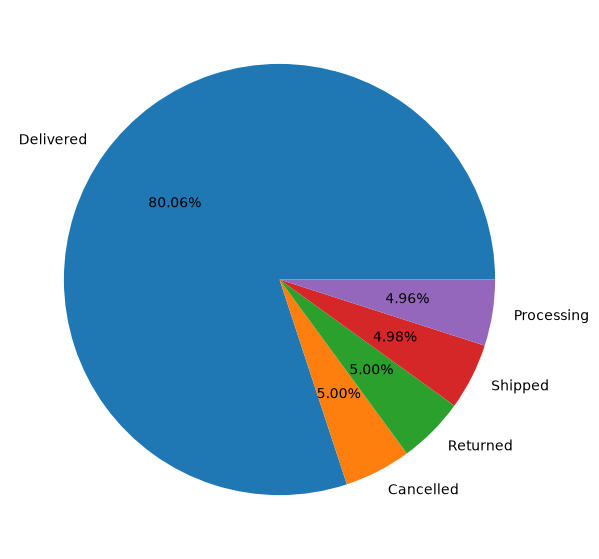

In [428]:
order_status_counts = sales.order_status.value_counts()
plt.pie(order_status_counts.values, labels=order_status_counts.index, autopct='%0.2f%%')

* 80 Percent of the orders are delivered.
* Cancelled and Returened makes 10 percent of the orders

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Amazing quality!'),
  Text(1, 0, 'Highly recommended!'),
  Text(2, 0, 'Excellent product!'),
  Text(3, 0, 'Value for money'),
  Text(4, 0, 'Nice quality'),
  Text(5, 0, 'Good product'),
  Text(6, 0, 'Could be better'),
  Text(7, 0, 'Okay'),
  Text(8, 0, 'Average product')])

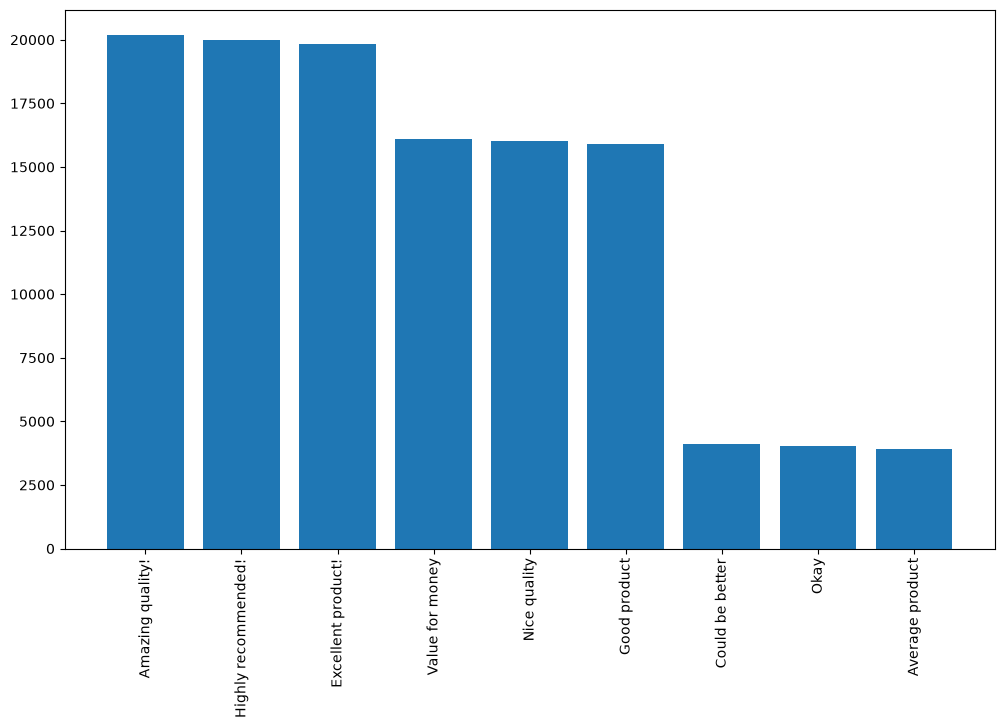

In [429]:
temp = sales[~(sales.review_text == 'NOT APPLICABLE')]
review_counts = temp.review_text.value_counts()

plt.bar(review_counts.index, review_counts.values)
plt.xticks(rotation='vertical')

* LEAST NUMBER Of Products Got NEGATIVE review

In [430]:
sales.rating.unique()

array([4.4, 4. , 5. , 3. ], dtype=float16)

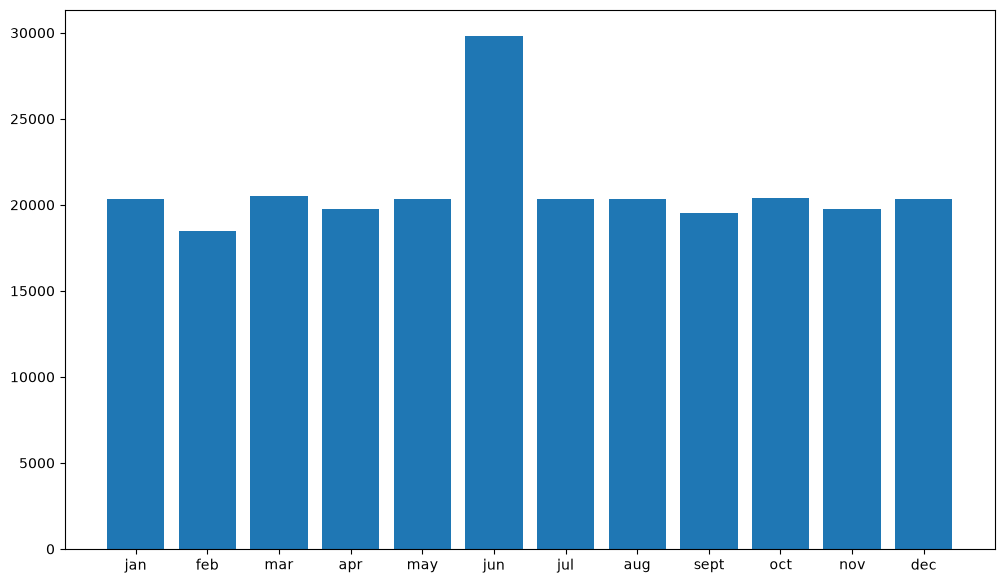

In [431]:
# Working on order_date
sales['sale_month'] = sales.order_date.apply(lambda x: int(x.split('-')[1]))
sorted(sales.sale_month.unique())

sale_month_count = sales.sale_month.value_counts()
plt.bar(sale_month_count.index, sale_month_count.values)
plt.xticks([1,2,3,4,5,6,7,8,9,10,11,12], ['jan','feb','mar','apr','may','jun','jul','aug','sept','oct','nov','dec'])
plt.show()

* Maximum Orders are recieved in the month of June.
* Rest all months have recieved alsmost same number of orders 

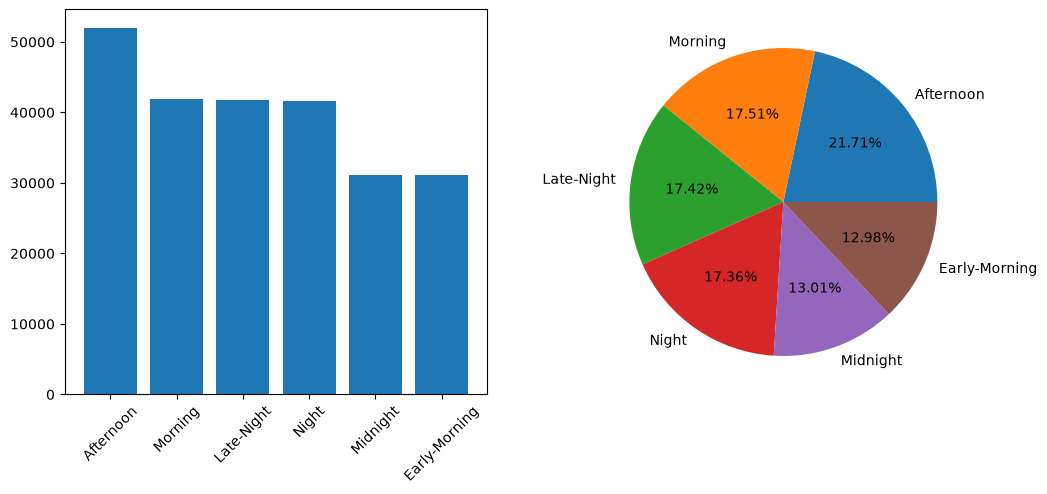

In [432]:
# Working on order time
def assignTimeStr(time):
    hr = int(time.split(':')[0])
    if hr > 0 and hr < 5:
        return 'Late-Night' 
    elif hr >= 5 and hr < 8:
        return 'Early-Morning'
    elif hr >= 8 and hr < 12:
        return 'Morning'
    elif hr >= 12 and hr < 17:
        return 'Afternoon'
    elif hr >= 17 and hr < 21:
        return 'Night'
    elif hr >= 21:
        return 'Midnight'
        

sales['time_group'] = sales.order_time.apply(assignTimeStr)

sale_time_group_count = sales.time_group.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(12, 5))
ax[0].bar(sale_time_group_count.index, sale_time_group_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(sale_time_group_count.values, labels=sale_time_group_count.index, autopct='%0.2f%%')


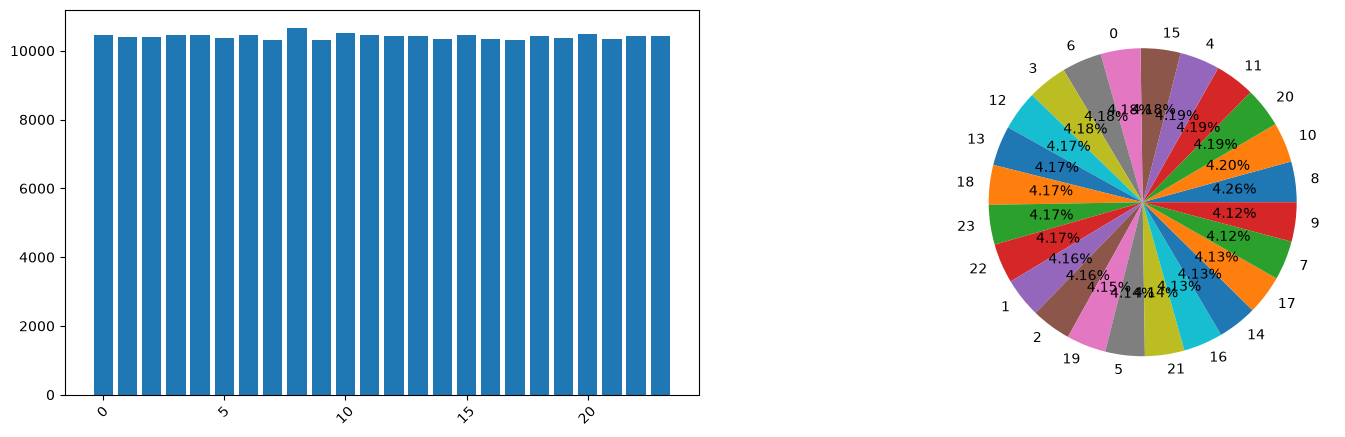

In [433]:
# Working on order_time
sales['time_int'] = sales.order_time.apply(lambda x: int(x.split(':')[0]))

sale_time_int_count = sales.time_int.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[0].bar(sale_time_int_count.index, sale_time_int_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(sale_time_int_count.values, labels=sale_time_int_count.index, autopct='%0.2f%%')

* Uniform Hourly Demand: Order volume remains virtually constant across all 24 hours of the day, averaging ~10,400 to 10,600 orders per hour (~4.17% of daily volume per hour) with no discernible peak or off-peak hours.

In [434]:
# Now I can drop - sale_month, time_group, time_int
sales.drop(columns=['sale_month', 'time_group', 'time_int'], inplace=True)

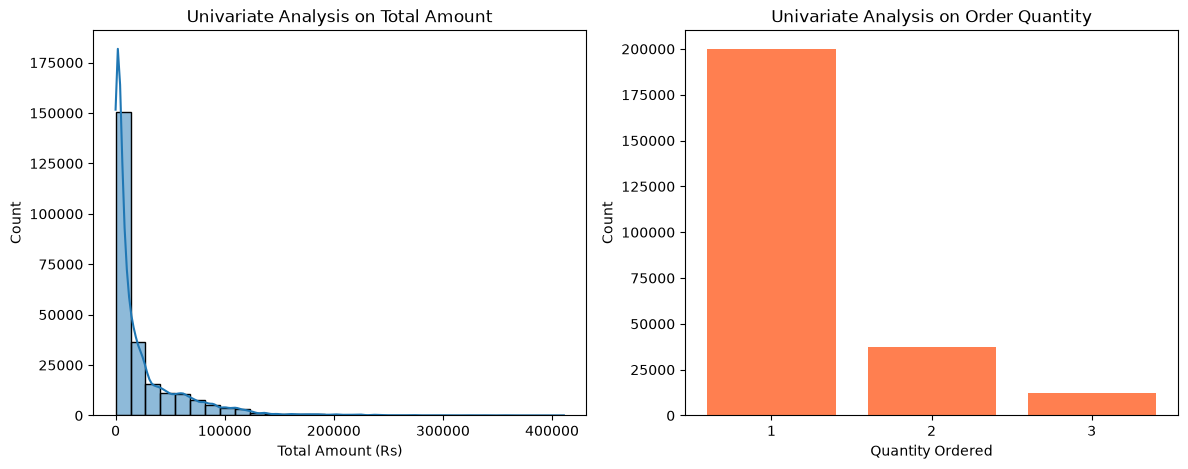

In [435]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.histplot(sales['total_amount'], bins=30, kde=True, ax=ax[0])
ax[0].set_title('Univariate Analysis on Total Amount')
ax[0].set_xlabel('Total Amount (Rs)')

quantity_counts = sales['quantity'].value_counts().sort_index()
ax[1].bar(quantity_counts.index.astype(str), quantity_counts.values, color='coral')
ax[1].set_title('Univariate Analysis on Order Quantity')
ax[1].set_xlabel('Quantity Ordered')
ax[1].set_ylabel('Count')

plt.show()

* Heavily Right-Skewed Spend (Total Amount): The distribution of Total Amount (Rs) is strongly right-skewed (positively skewed). The vast majority of orders (~150,000+ transactions, or ~60% of the ~250,000 dataset) are concentrated in the lowest price bracket (Rs 0 – Rs 15,000), with frequencies dropping sharply between Rs 15,000 and Rs 1,00,000.

* Single-Unit Dominance (Order Quantity): Quantity Ordered is a discrete variable strictly bounded between 1 and 3 units:   
    - 1 Unit: ~200,000 orders (~80% of all transactions)   
    - 2 Units: ~37,500 orders (~15% of all transactions)   
    - 3 Units: ~12,500 orders (~5% of all transactions)

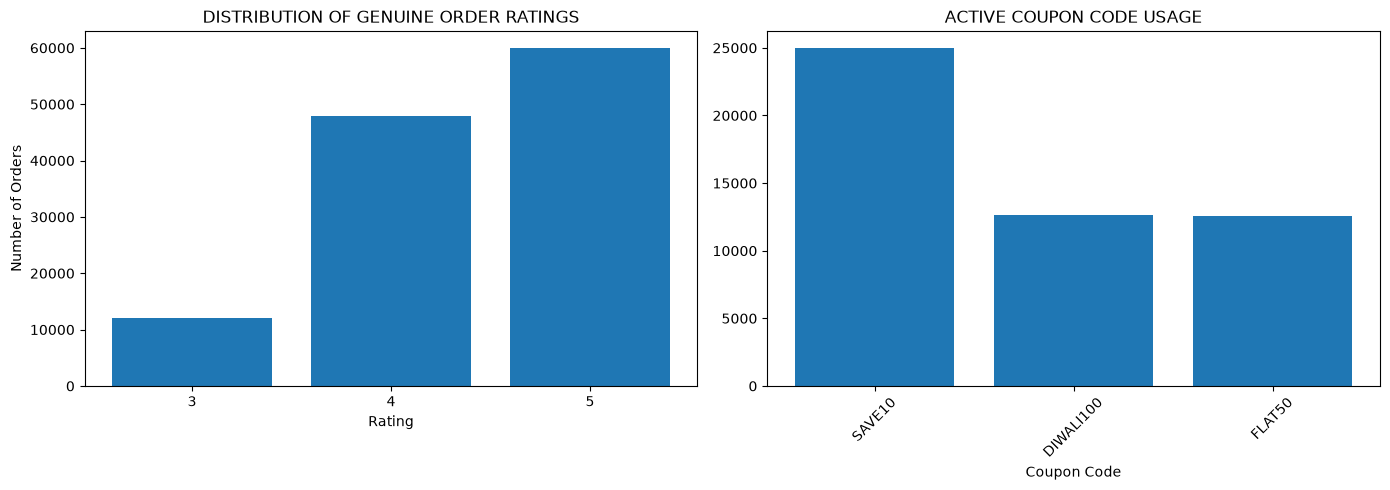

In [436]:
# Univariate Analysis on Categorical/Ordinal Columns: rating & coupon_code
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Filtering out the float16 mean (~4.398) to plot only genuine whole-number ratings (3.0, 4.0, 5.0)
genuine_ratings = sales[sales.rating % 1 == 0].rating.astype(int).value_counts().sort_index()

ax[0].bar(genuine_ratings.index.astype(str), genuine_ratings.values)
ax[0].set_title("DISTRIBUTION OF GENUINE ORDER RATINGS")
ax[0].set_xlabel("Rating")
ax[0].set_ylabel("Number of Orders")

# Filtering out 'NOT APPLICABLE' to see top active coupons
active_coupons = sales[sales.coupon_code != "NOT APPLICABLE"].coupon_code.value_counts()
ax[1].bar(active_coupons.index, active_coupons.values)
ax[1].set_title("ACTIVE COUPON CODE USAGE")
ax[1].set_xlabel("Coupon Code")
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

* Left-Skewed Positive Ratings (Distribution of Genuine Order Ratings): Among the ~120,000 rated orders (~48% of the total ~250,000 dataset), ratings are strictly bounded between 3 and 5 stars with a complete absence of 1-star and 2-star reviews:   
    - 5 Stars: ~60,000 orders (50.0% of rated orders | ~24.0% of total orders)   
    - 4 Stars: ~48,000 orders (40.0% of rated orders | ~19.2% of total orders)   
    - 3 Stars: ~12,000 orders (10.0% of rated orders | ~4.8% of total orders)   
    - Unrated / Filtered Share: The remaining ~130,000 orders (~52% of the dataset) do not have a genuine rating (indicating either missing/unsubmitted reviews or cancelled/returned orders where ratings were not applicable)

* Coupon Redemption Concentration (Active Coupon Code Usage): Across the ~50,000 orders (~20% of the total dataset) where a promotional coupon was applied, usage follows an exact 2 : 1 : 1 ratio:   
    - SAVE10: ~25,000 orders (50.0% of coupon orders | ~10.0% of total orders)   
    - DIWALI100: ~12,500 orders (25.0% of coupon orders | ~5.0% of total orders)   
    - FLAT50: ~12,500 orders (25.0% of coupon orders | ~5.0% of total orders)   
    - Non-Coupon Baseline: Approximately ~200,000 orders (~80% of all transactions) were completed without an active coupon code. 

* 90% of all submitted ratings are positive (4 or 5 stars). Meanwhile, percentage-based discounting (SAVE10) drives twice the redemption volume of flat-rate (FLAT50) or seasonal (DIWALI100) codes. Given the high-ticket right tail (up to Rs 4,00,000) observed in Total Amount, a 10% discount yields far greater monetary savings on mid-to-high-value baskets than fixed Rs 50 or Rs 100 discounts.

In [437]:
sales.rating.unique()

array([4.4, 4. , 5. , 3. ], dtype=float16)

# UNIVARIATE ANALYSIS on PRODUCT table

### Summary of univariate analysis of the product table

    - All products are equally present
    - Top 7 Brands (as per the number of products present) with Nike and Puma leading
    - Ratings
        * The rating is Normally Distributed
        * Majority of the ratings falls 4.3 and 4.5

In [438]:
products.columns

Index(['product_id', 'product_name', 'category', 'brand', 'original_price',
       'discount_percent', 'discount_amount', 'selling_price',
       'stock_quantity', 'weight_kg', 'avg_rating', 'total_reviews'],
      dtype='str')

In [439]:
products.isnull().sum()

product_id          0
product_name        0
category            0
brand               0
original_price      0
discount_percent    0
discount_amount     0
selling_price       0
stock_quantity      0
weight_kg           0
avg_rating          0
total_reviews       0
dtype: int64

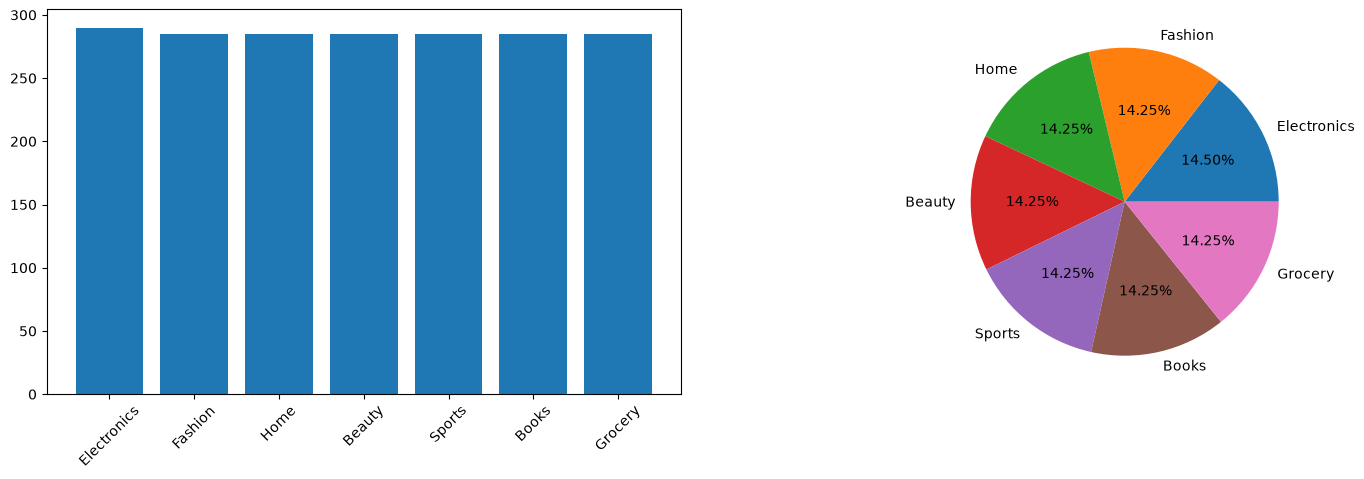

In [440]:
category_count = products.category.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[0].bar(category_count.index, category_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(category_count.values, labels=category_count.index, autopct='%0.2f%%')

* Uniform Category Distribution (Product Share by Category): The product catalog is evenly distributed across all 7 categories, closely matching a theoretical uniform split ($\frac{1}{7} \approx 14.29\%$)

Text(0.5, 1.0, 'PRODUCT SHARE BY CATEGORY')

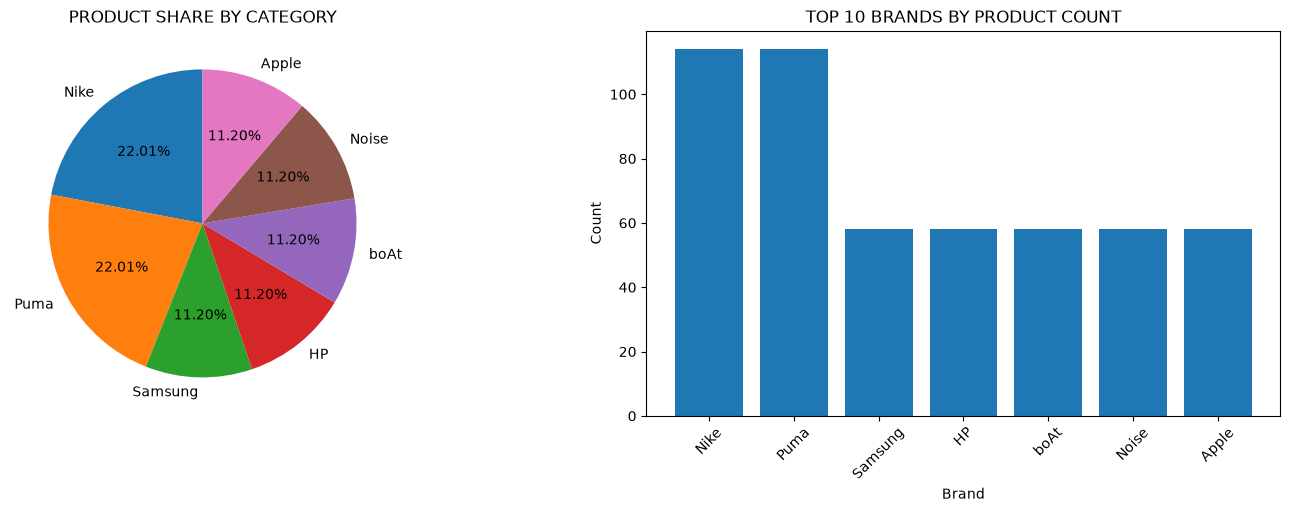

In [441]:
temp = products.brand.value_counts().sort_values(ascending=False).head(7)

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[1].bar(temp.index, temp.values)
ax[1].tick_params(axis='x', rotation=45)
ax[1].set_title("TOP 10 BRANDS BY PRODUCT COUNT")
ax[1].set_xlabel("Brand")
ax[1].set_ylabel("Count")

ax[0].pie(temp.values, labels=temp.index, autopct='%0.2f%%', startangle=90)
ax[0].set_title("PRODUCT SHARE BY CATEGORY")

* Bimodal Brand Step-Function (Top 10 Brands by Product Count): Rather than following a natural Pareto curve, brand product counts fall into two discrete tiers:   Tier 1 (~114–115 products each): Nike and Puma lead the catalog with nearly twice the product count of any other brand.   Tier 2 (~57–58 products each): Samsung, HP, boAt, Noise, Apple, Levis, Peter, and Titan all have virtually identical product counts at exactly half the volume of Nike and Puma

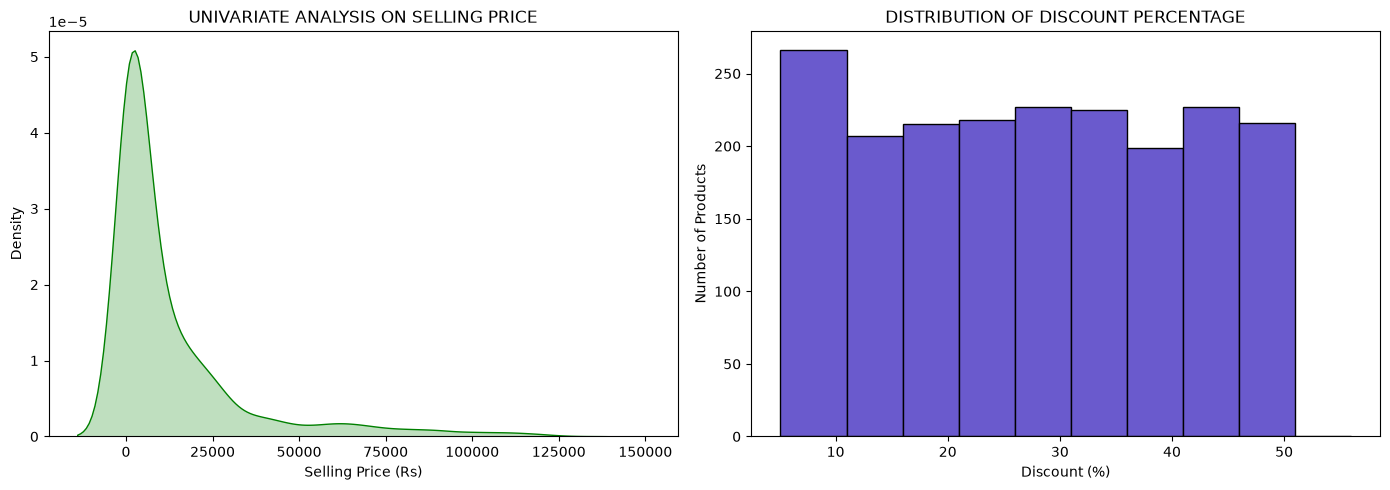

In [442]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.kdeplot(products.selling_price, fill=True, color='green', ax=ax[0])
ax[0].set_title("UNIVARIATE ANALYSIS ON SELLING PRICE")
ax[0].set_xlabel("Selling Price (Rs)")

plt.hist(products.discount_percent, bins=[5,11,16,21,26,31,36,41,46,51,56], color='slateblue', edgecolor='black')
ax[1].set_title("DISTRIBUTION OF DISCOUNT PERCENTAGE")
ax[1].set_xlabel("Discount (%)")
ax[1].set_ylabel("Number of Products")

plt.tight_layout()
plt.show()

* Right-Skewed Product Pricing (Selling Price): The KDE curve for Selling Price (Rs) is strongly right-skewed (positively skewed). The highest density of products (~5e-5 peak) is concentrated between Rs 500 and Rs 15,000, with density tapering off sharply past Rs 35,000

* High-Ticket Catalog Tail & Total Amount Link: A subtle secondary plateau appears around Rs 55,000 – Rs 75,000, and the upper tail stretches to ~Rs 1,25,000 – Rs 1,35,000. This directly explains the ~Rs 4,00,000 maximum observed earlier in Total Amount: purchasing the maximum 3 units of a top-tier product (~Rs 1,33,000) equals ~Rs 4,00,000 ($3 \times 1,33,333 \approx 4,00,000$)

* Balanced Density: Each 5% bucket consistently contains ~200 to 230 products (roughly 10% to 11.5% of the 2,000-product catalog per bucket), with the initial 5–10% bucket naturally slightly higher (~265 products) due to capturing six integer increments instead of five

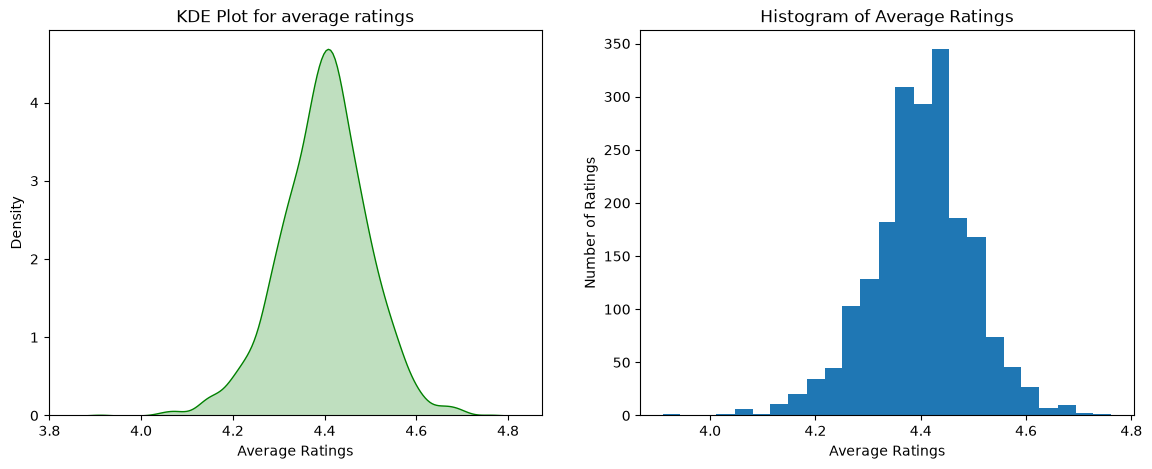

In [443]:
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(14, 5))

sns.kdeplot(products.avg_rating, fill=True, color='green', ax=ax[0])
ax[0].set_title("KDE Plot for average ratings")
ax[0].set_xlabel("Average Ratings")

plt.hist(products.avg_rating, bins=25)
ax[1].set_title("Histogram of Average Ratings")
ax[1].set_xlabel("Average Ratings")
ax[1].set_ylabel("Number of Ratings")

plt.show()

* The rating is Normally Distributed
* Majority of the ratings falls 4.3 and 4.6
* There are very few outliers extending below 4.0 or above 4.7, indicating a generally high and consistent satisfaction level with minimal extreme variance


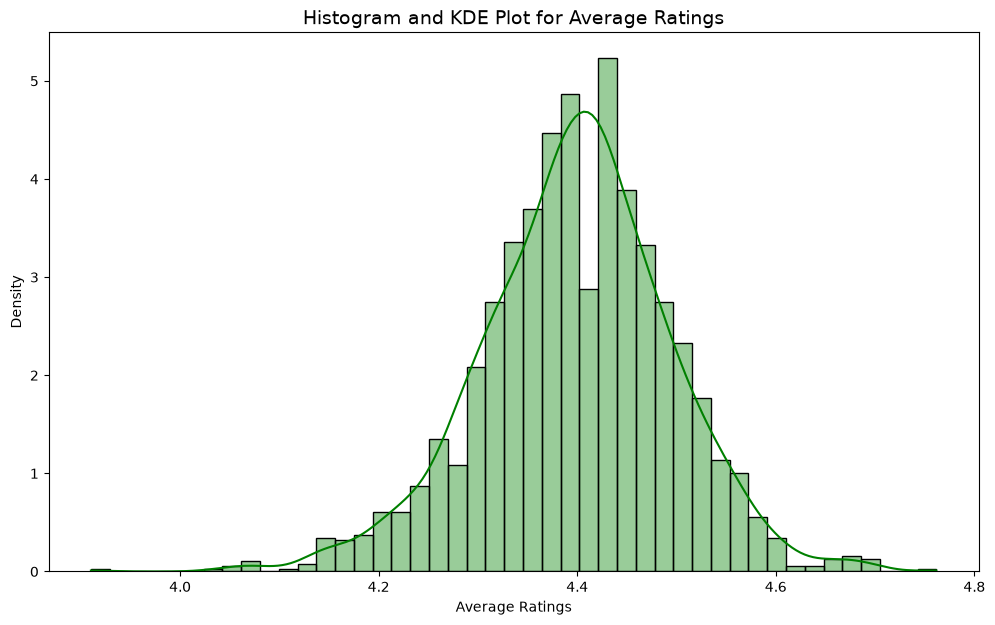

In [444]:
# Plot the histogram with a density norm, and overlay the KDE curve
sns.histplot(
    products.avg_rating,
    kde=True,
    stat="density",
    color="green",
    edgecolor="black",
    alpha=0.4,
)

plt.title("Histogram and KDE Plot for Average Ratings", fontsize=14)
plt.xlabel("Average Ratings")
plt.ylabel("Density")

plt.show()

<Axes: xlabel='stock_quantity', ylabel='Count'>

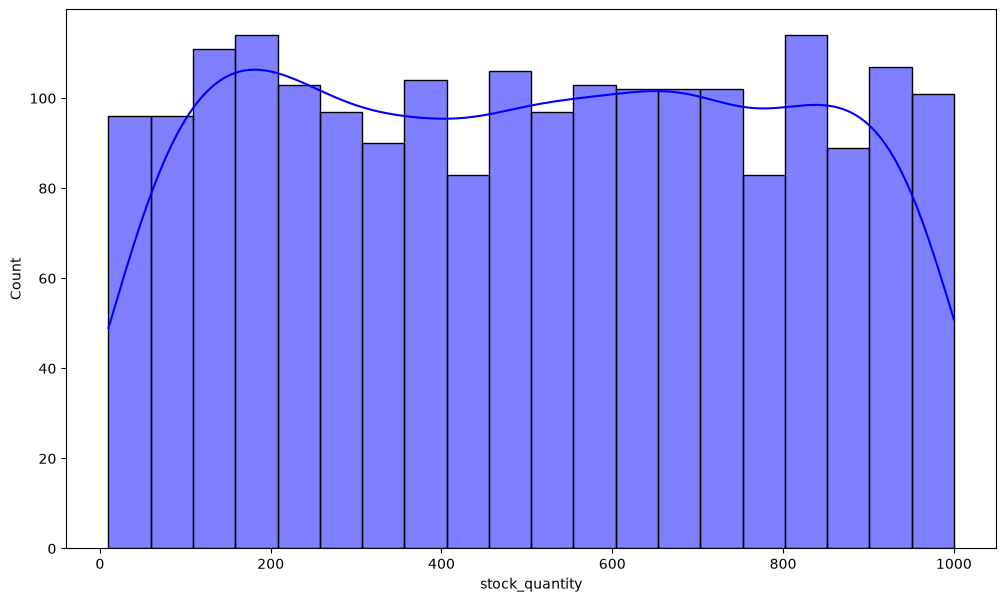

In [445]:
sns.histplot(products.stock_quantity, bins=20, kde=True, color='blue')

# BIVARIATE ANALYSIS and MULTIVARIATE ANALYSIS

In [446]:
customers.columns

Index(['customer_id', 'customer_name', 'gender', 'age', 'email', 'city',
       'state', 'pincode', 'registration_date', 'customer_tier',
       'total_orders', 'total_spent'],
      dtype='str')

<Axes: xlabel='age', ylabel='Density'>

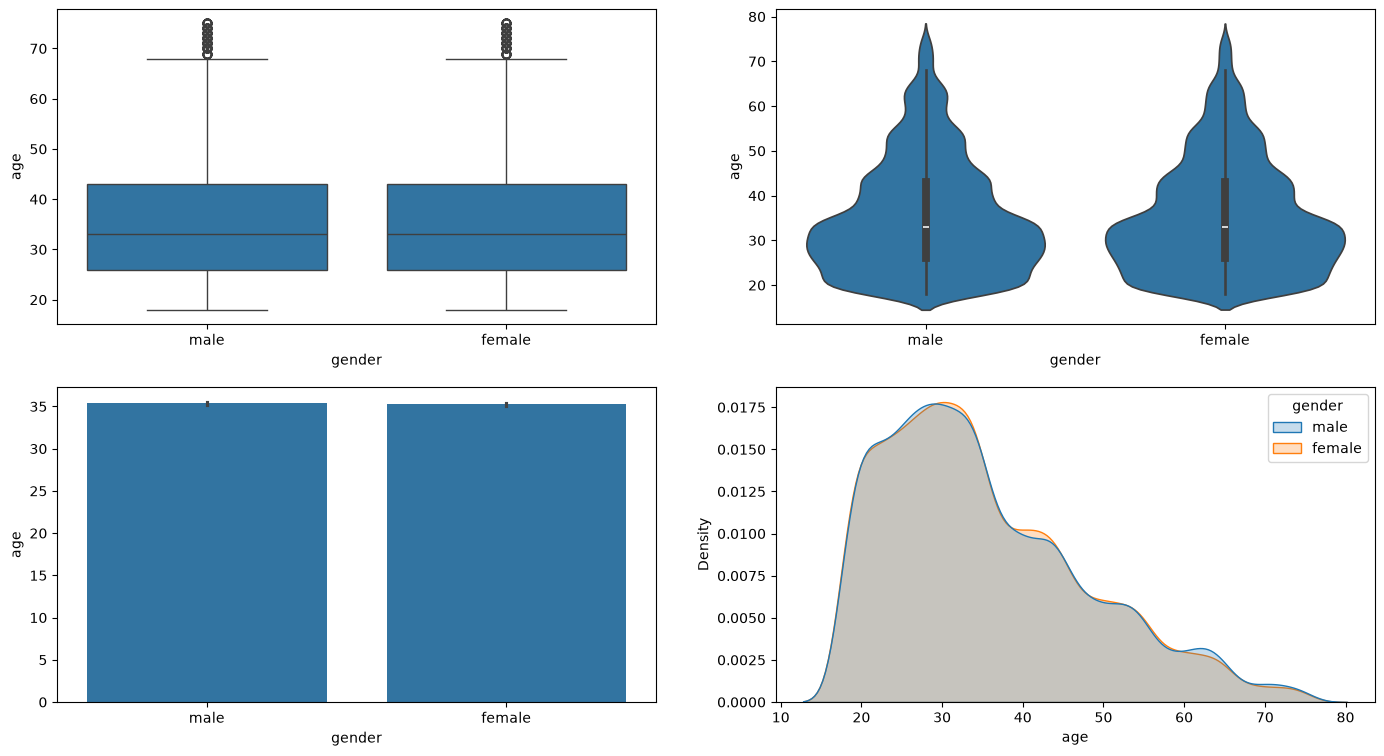

In [447]:
# Gender and Age
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='gender', y='age', ax=ax[0,0])
sns.violinplot(data=customers, x='gender', y='age', ax=ax[0,1])
sns.barplot(data=customers, x='gender', y='age', ax=ax[1,0])
sns.kdeplot(data=customers, x='age', hue='gender', fill=True)

* The distribution of age is identical between males and females. There is no relationship between AGE and GENDER
* There are a few outliers (boxplot)
* Average age of males and females are equal (around 35)
* Median age is around 32

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Punjab'),
  Text(1, 0, 'West Bengal'),
  Text(2, 0, 'Haryana'),
  Text(3, 0, 'UP'),
  Text(4, 0, 'Rajasthan'),
  Text(5, 0, 'Karnataka'),
  Text(6, 0, 'Maharashtra'),
  Text(7, 0, 'Delhi'),
  Text(8, 0, 'Tamil Nadu'),
  Text(9, 0, 'Gujarat')])

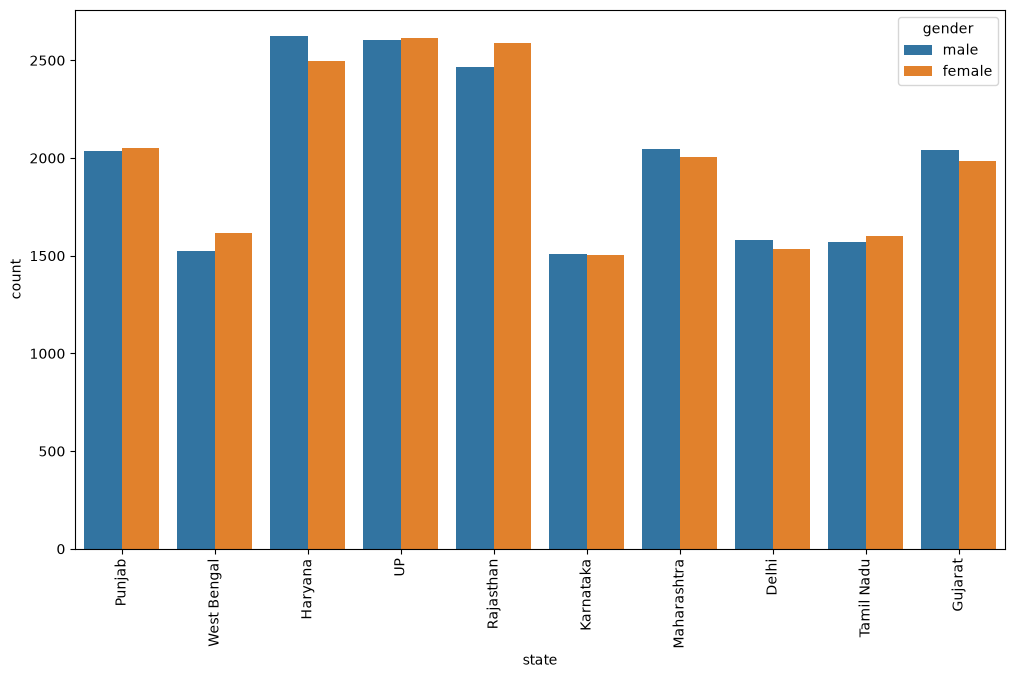

In [448]:
# Gender and State
sns.countplot(data=customers, x="state", hue="gender")
plt.xticks(rotation='vertical')

* Customers from UP, Haryana, Rajasthan dominate, followed by Maharastra and Gujarat (Central and North India)
* The distribution of males and females within a state is almost identical

([0, 1], [Text(0, 0, 'male'), Text(1, 0, 'female')])

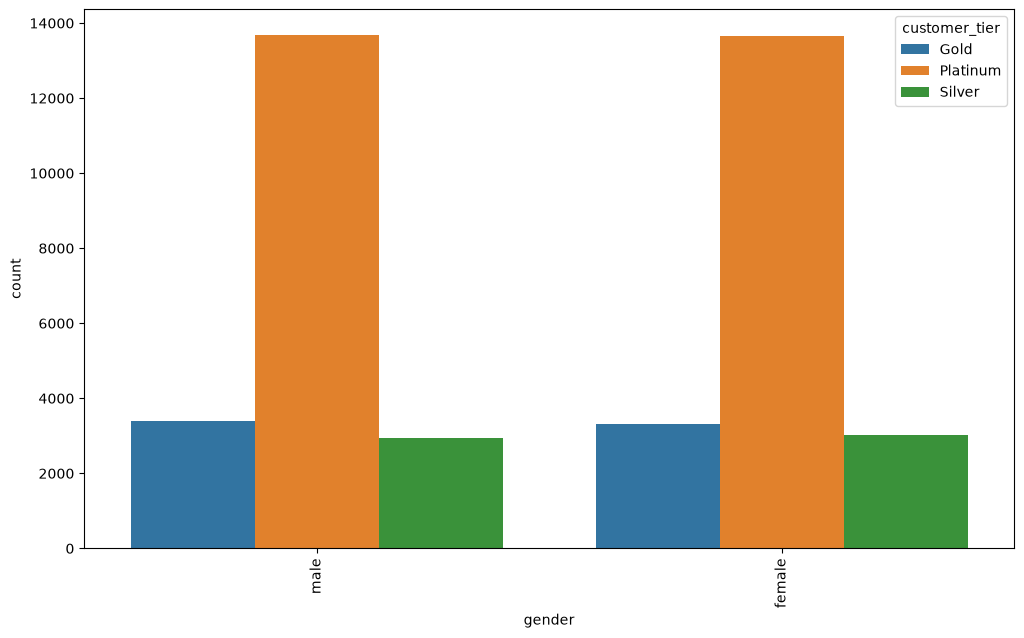

In [449]:
# Gender and Customer Tier
sns.countplot(data=customers, x="gender", hue="customer_tier")
plt.xticks(rotation='vertical')

* Males and Females predominantly have PLATINUM membership

<Axes: xlabel='gender'>

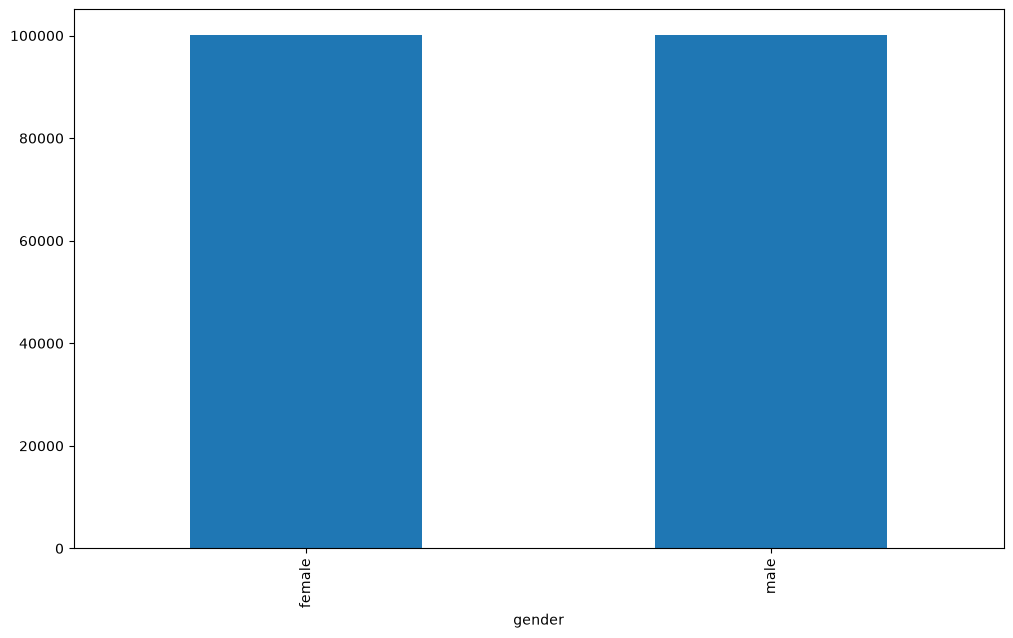

In [450]:
# Gender and total_orders
customers.groupby('gender')['total_orders'].sum().plot(kind='bar')

<Axes: xlabel='gender'>

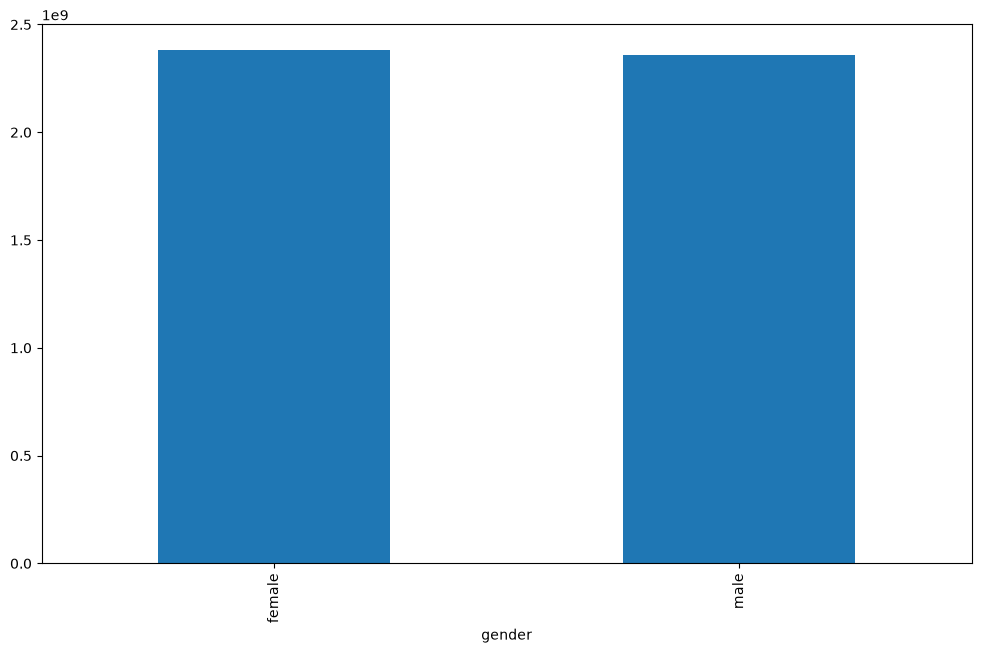

In [451]:
# Gender and total_spent
customers.groupby('gender')['total_spent'].sum().plot(kind='bar')

* Males and Females have spent equally and have ordered equally

<Axes: xlabel='state', ylabel='age'>

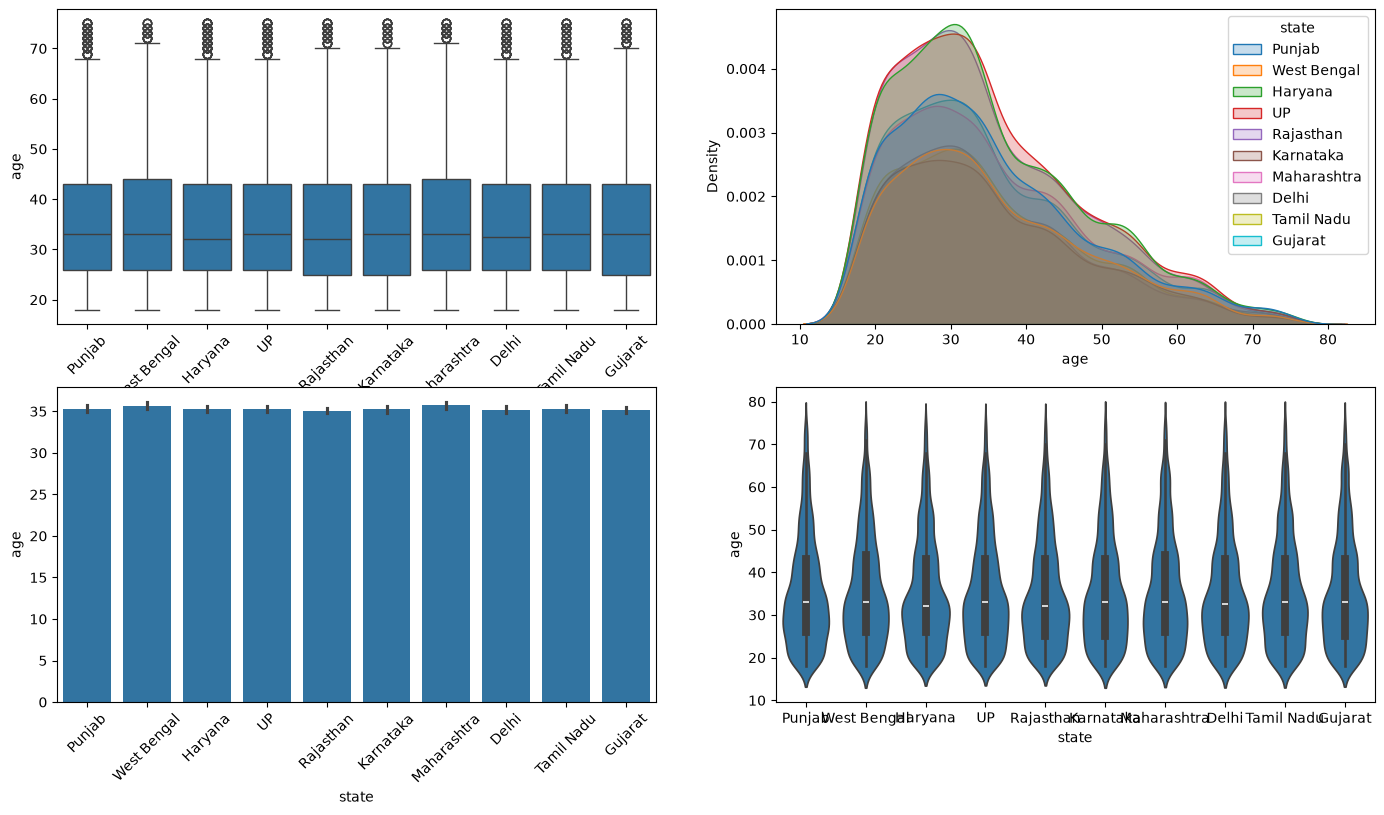

In [452]:
# Age and State
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='state', y='age', ax=ax[0,0])
ax[0,0].tick_params(axis='x', rotation=45)

sns.kdeplot(data=customers, x='age', hue='state', ax=ax[0,1], fill=True)

sns.barplot(data=customers, x='state', y='age',  ax=ax[1,0])
ax[1,0].tick_params(axis='x', rotation=45)

sns.violinplot(data=customers, x='state', y='age', ax=ax[1,1])

* Average age across the states are similar (around 35)
* There are a few outliers
* Data is right skewed, that is probability of a person being in the age group of 20-40 is more

<Axes: xlabel='customer_tier', ylabel='age'>

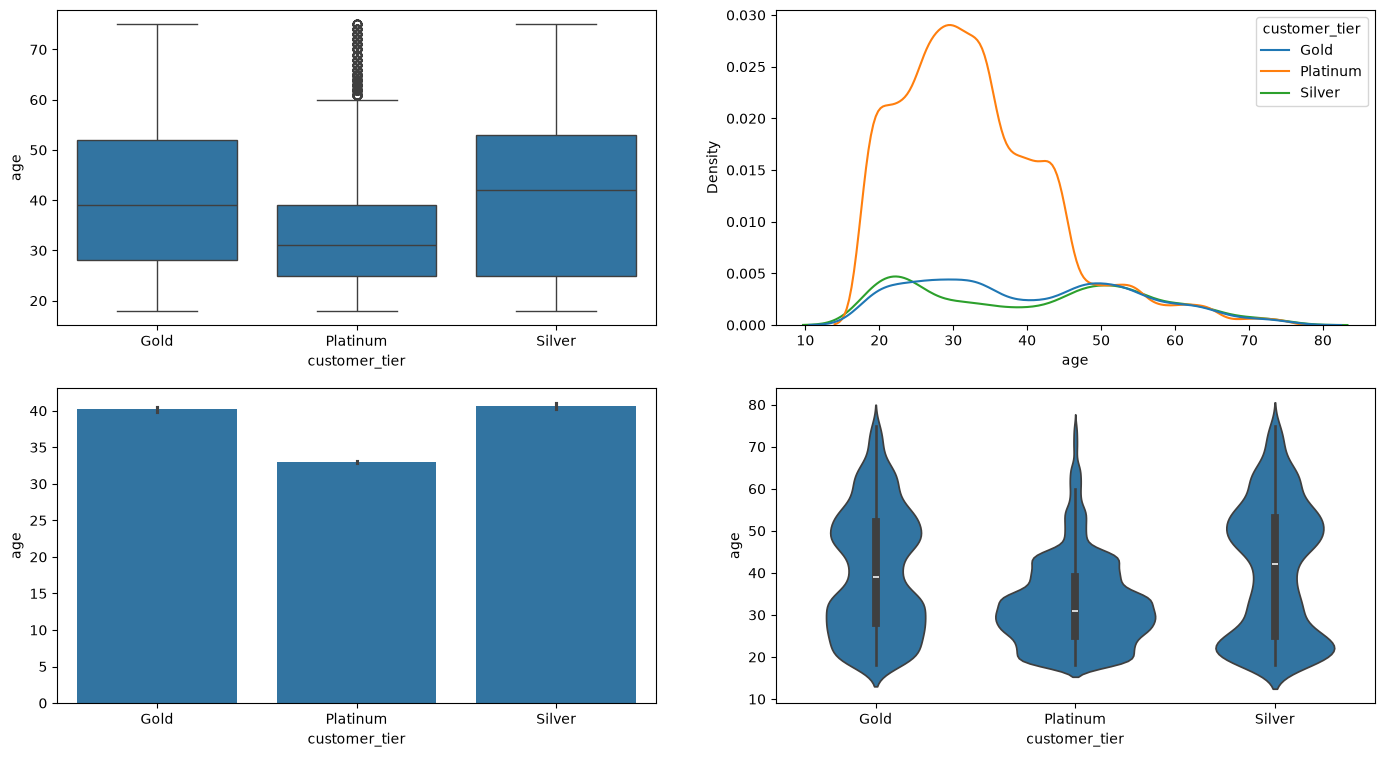

In [453]:
# Age and Customer Tier
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='customer_tier', y='age', ax=ax[0,0])
sns.kdeplot(data=customers, x='age', hue='customer_tier', ax=ax[0,1])
sns.barplot(data=customers, x='customer_tier', y='age',  ax=ax[1,0])
sns.violinplot(data=customers, x='customer_tier', y='age', ax=ax[1,1])

* Gold Tier
    - Median Age around 39
    - Average Age around 40
    - Bimodal Distribution

* Platinum Tier
    - Median Age around 31
    - Average Age around 33
    - Have lots of outliers >60
    - They are relatively younger
    - Right skewed
    - Customers are concentrated more in the age group 20-40

* Silver Tier
    - Median Age around 42
    - Average Age around 40.5
    - Bimodal Distribution

<Axes: xlabel='total_orders', ylabel='age'>

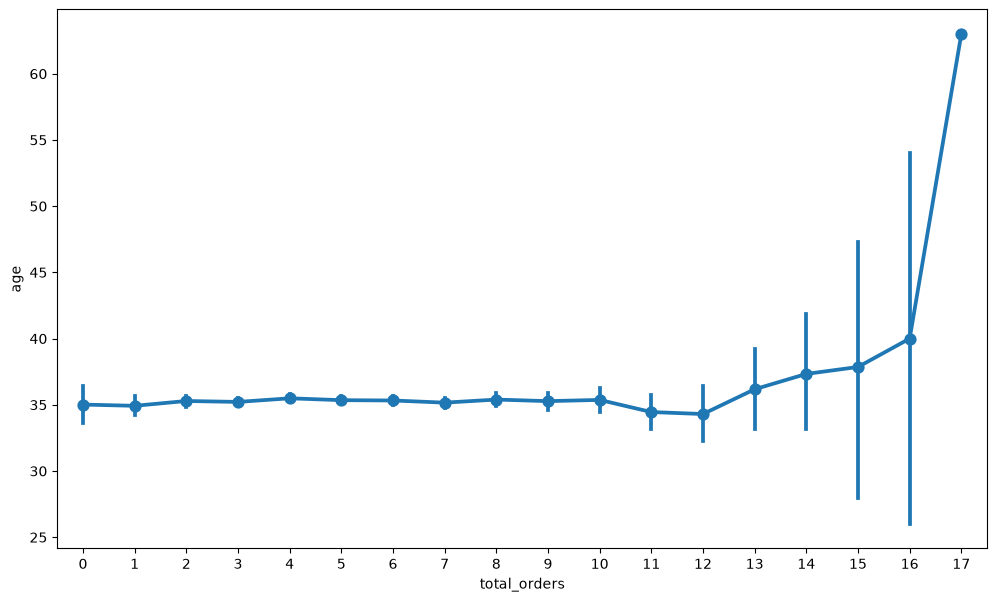

In [454]:
# Age and Total Orders
sns.pointplot(data=customers, x='total_orders', y='age')

<Axes: xlabel='total_orders', ylabel='age'>

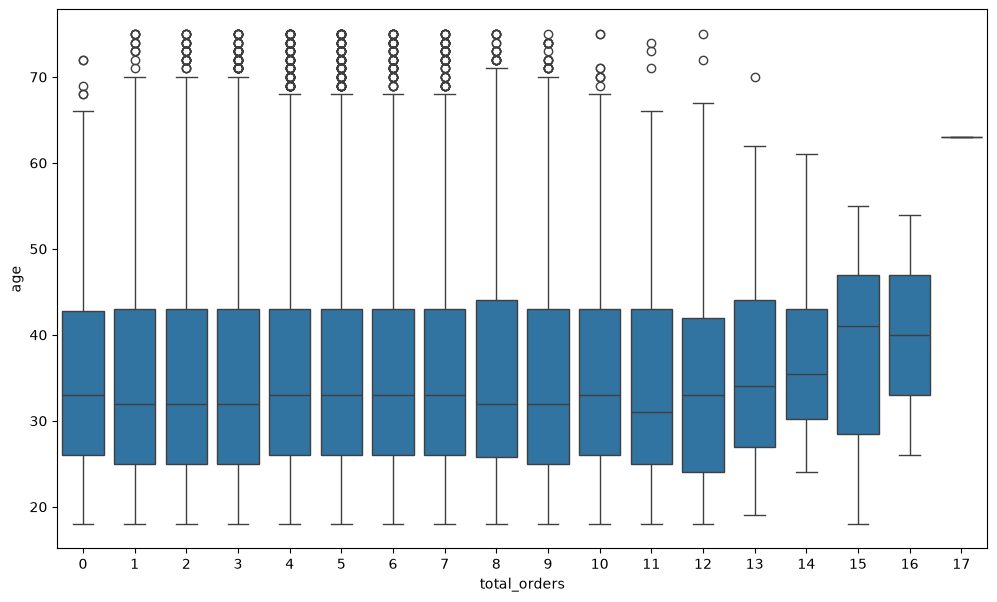

In [455]:
sns.boxplot(data=customers, x="total_orders", y="age")

* No Oberservation is possible for age with total orders

<Axes: xlabel='age_group', ylabel='total_spent'>

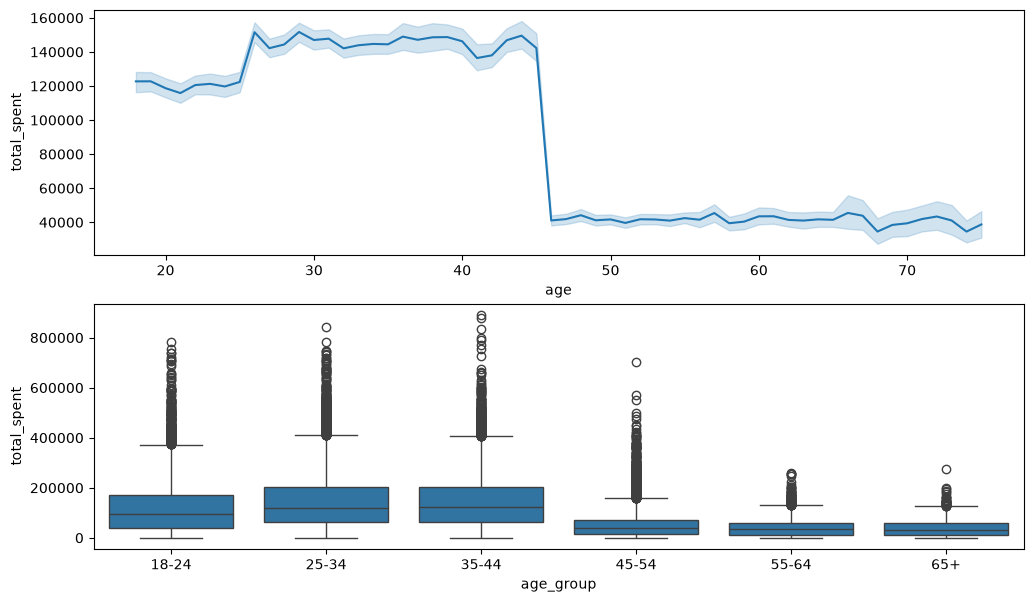

In [456]:
# Age with total spent
fig,ax=plt.subplots(nrows=2)

sns.lineplot(data=customers, x='age', y='total_spent', ax=ax[0])

bins = [18, 25, 35, 45, 55, 65, 80]
labels = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
customers["age_group"] = pd.cut(customers["age"], bins=bins, labels=labels, right=False)

sns.boxplot(data=customers, x="age_group", y="total_spent", ax=ax[1])

* Sharp Spending Drop at Age 45: Average customer spending drops dramatically around age 45, falling from ~140,000–150,000 for customers under 45 down to ~40,000 for those aged 46 and older.
* Interquartile range (IQR) compressing significantly after age 45, with the median spend collapsing from over ~120,000 to under ~40,000.
* While extreme spenders (>600k) are prevalent in the 18–44 groups and present in 45–54, spending above 300k virtually vanishes for customers aged 55+

<Axes: xlabel='customer_tier', ylabel='city'>

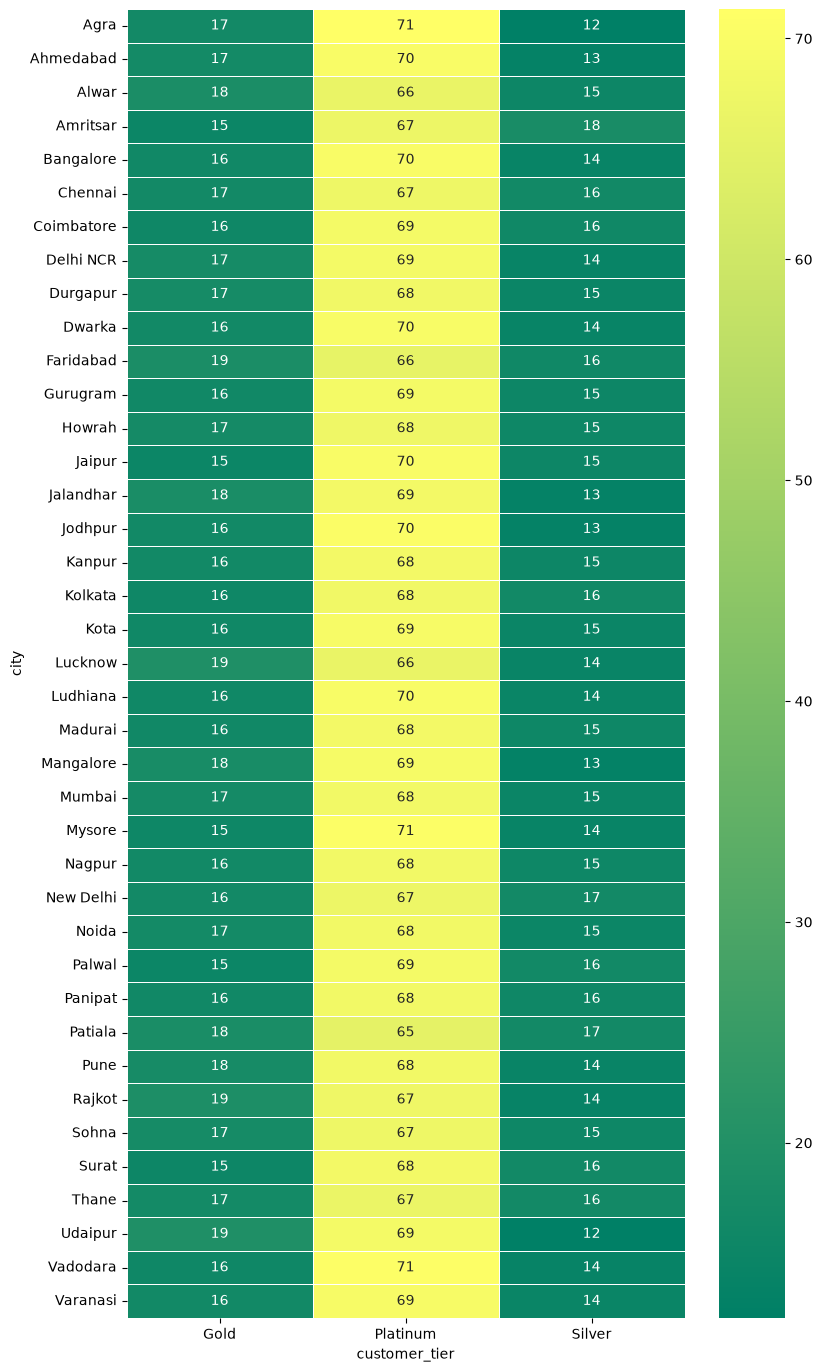

In [457]:
# city with customer_tire
grid = pd.crosstab(customers.city, customers.customer_tier, normalize="index")*100
plt.figure(figsize=(9,17))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

* No Geographic Dependency: There is no relationship between a customer's tier and the city in which they live.

* Consistent Distribution: Platinum accounts for roughly 65%–76% of memberships across all cities, while the remainder is split almost evenly between Gold (~15%–20%) and Silver (~12%–19%).

<Axes: xlabel='total_orders', ylabel='city'>

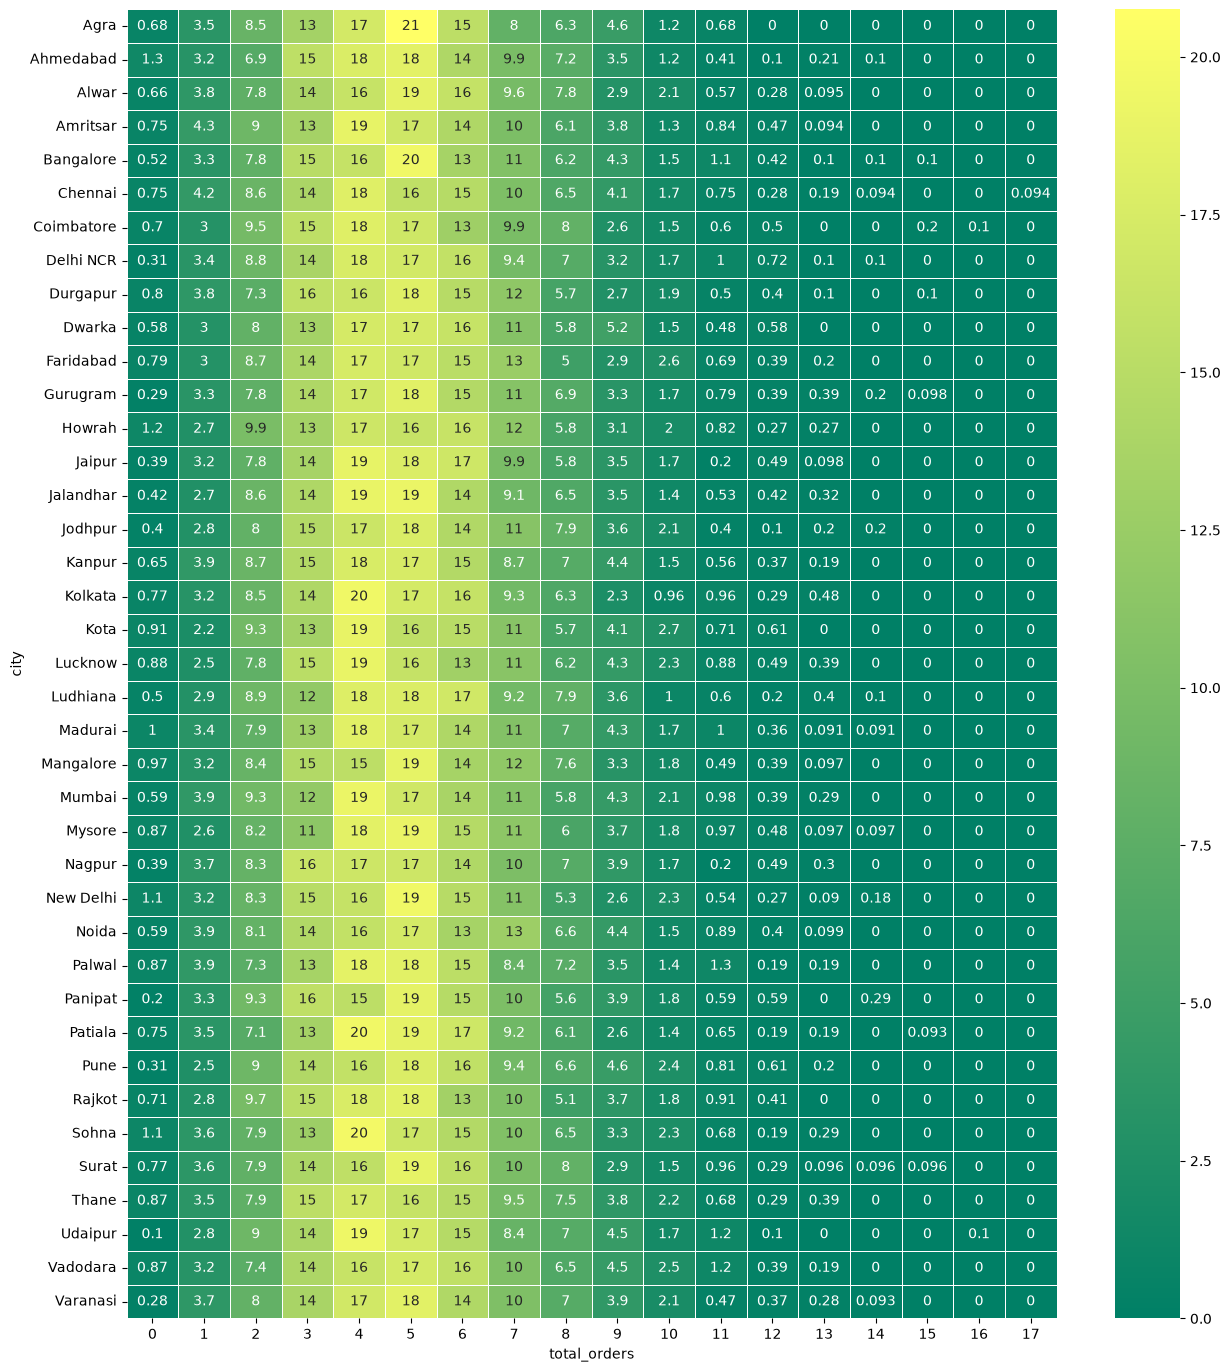

In [458]:
# City and Total_orders
grid = pd.crosstab(customers["city"], customers["total_orders"], normalize="index")*100
plt.figure(figsize=(15,17))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

* There is no relationship between the orders_placed and the city
* Across all cities, customer purchase frequency is concentrated between 2 and 8 total orders, accounting for roughly 85%–90% of the customer base, with order count 5 being the mode (~17%–21%)

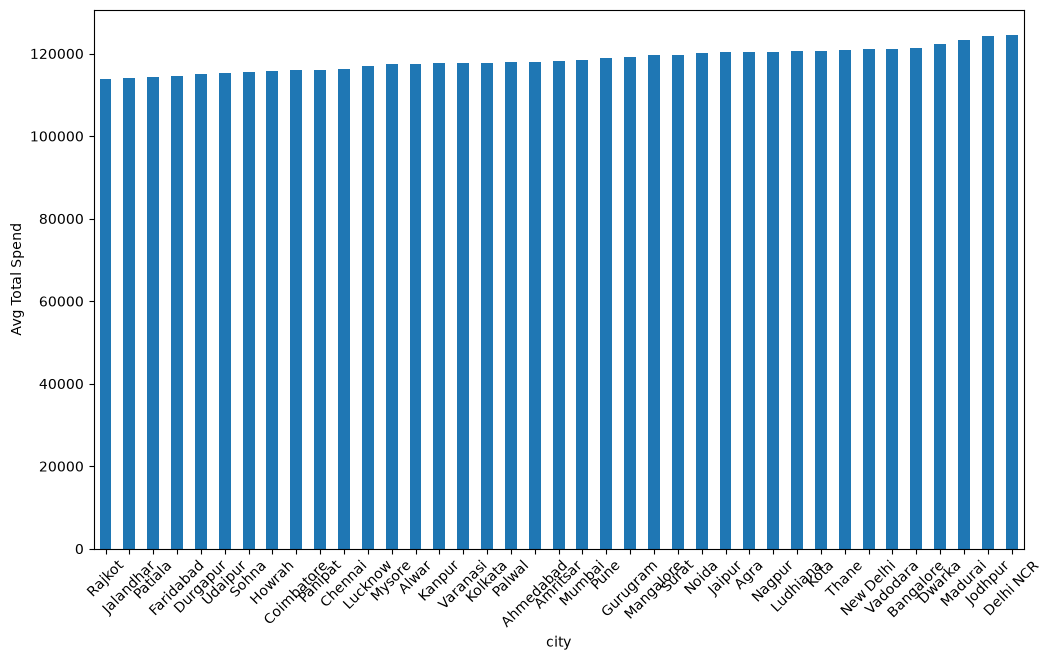

In [459]:
# city and total spending
customers.groupby('city')['total_spent'].mean().sort_values(ascending=True).plot(kind='bar')
plt.ylabel("Avg Total Spend")
plt.xticks(rotation=45)
plt.show()

* There is no noticeable relationship between total spending and city
* Average total spend across all cities hovers tightly between ~114,000 and 124,000, indicating that geography does not drive customer purchasing power

<Axes: xlabel='customer_tier', ylabel='state'>

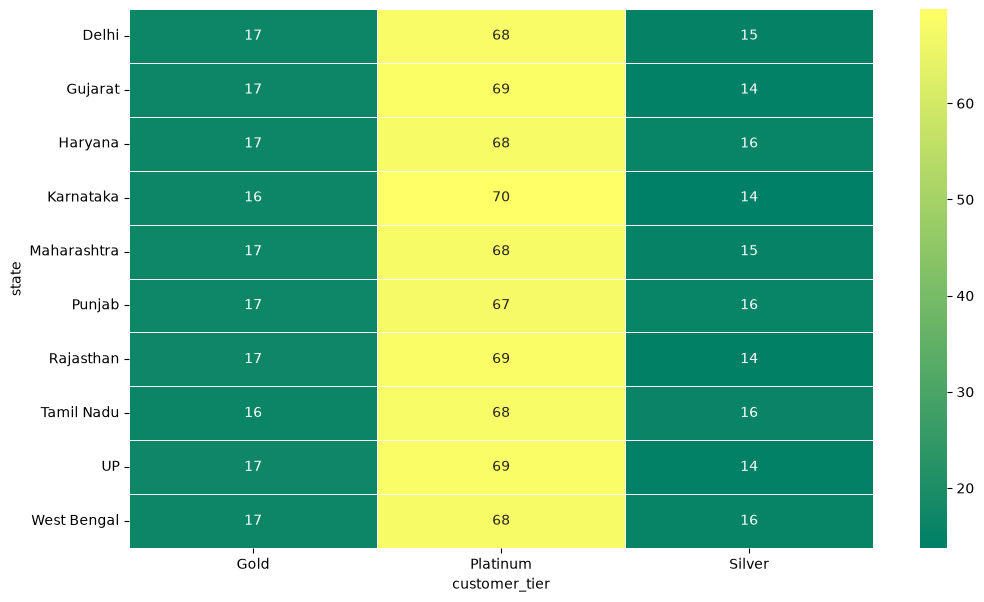

In [460]:
# state with customer_tire
grid = pd.crosstab(customers.state, customers.customer_tier, normalize="index")*100
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

<Axes: xlabel='total_orders', ylabel='state'>

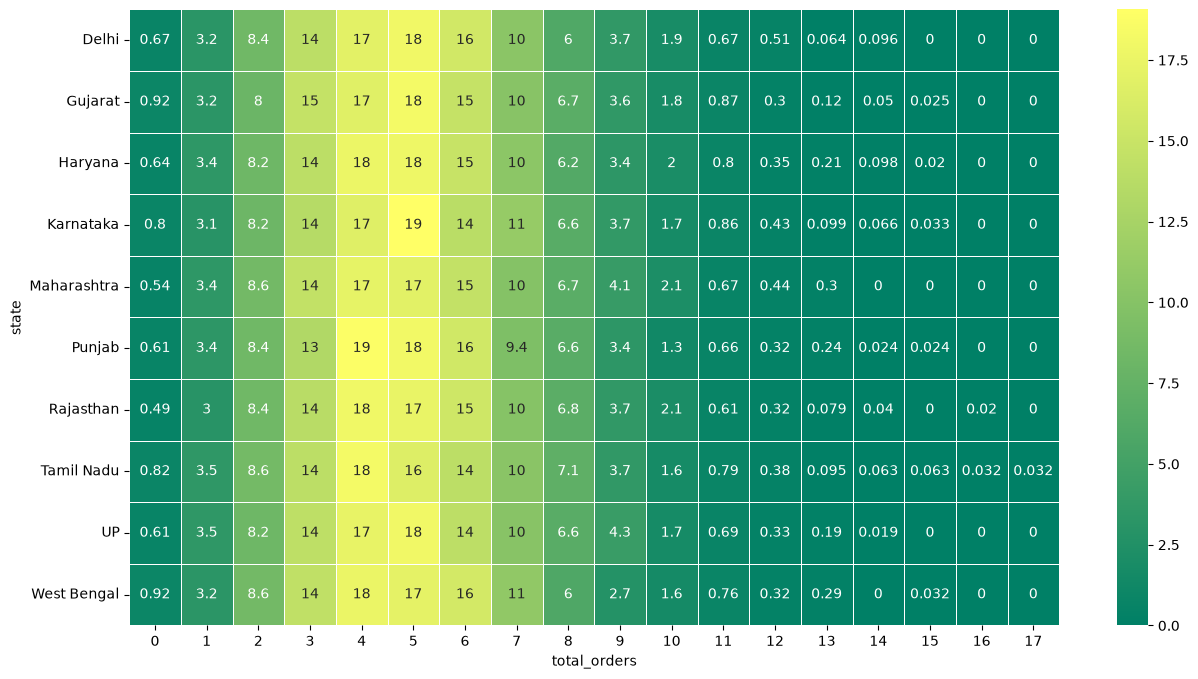

In [461]:
# State and Total_orders
grid = pd.crosstab(customers["state"], customers["total_orders"], normalize="index")*100
plt.figure(figsize=(15,8))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

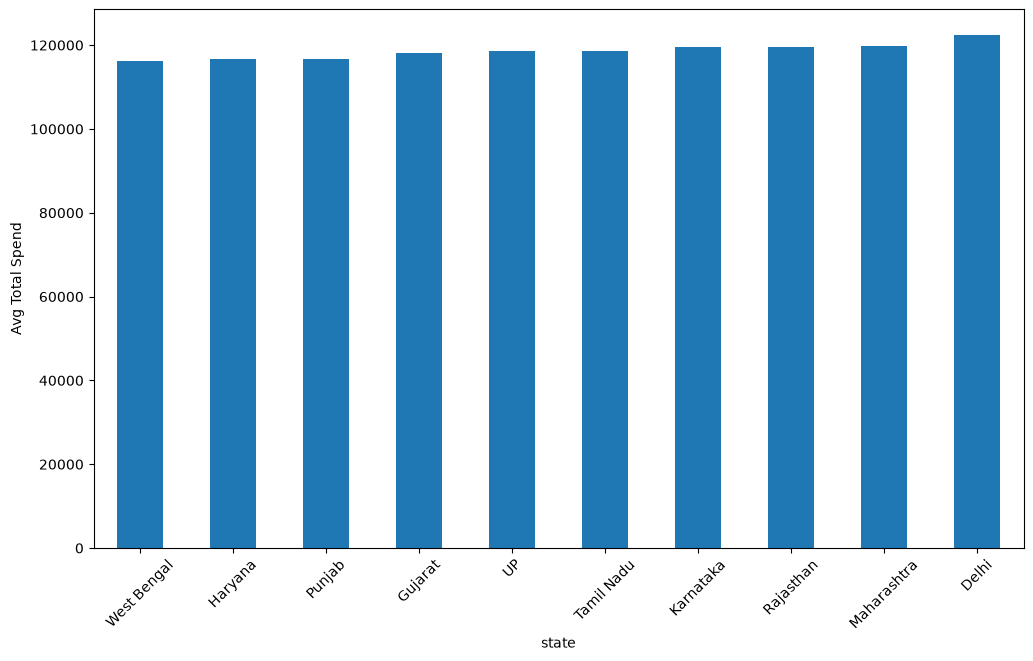

In [462]:
# state and total spending
customers.groupby('state')['total_spent'].mean().sort_values(ascending=True).plot(kind='bar')
plt.ylabel("Avg Total Spend")
plt.xticks(rotation=45)
plt.show()

* No Geographic Dependency: There is no relationship between a customer's tier and the state in which they live.
* Consistent Distribution: Platinum accounts for roughly 68%-70% of memberships across all cities, while the remainder is split almost evenly between Gold and Silver.

* There is no relationship between the orders_placed and the state
* Across all cities, customer purchase frequency is concentrated between 2 and 7 total orders, accounting for roughly 85%–90% of the customer base, with order count 4 and 5 being the mode (~17%–20%)

* There is no noticeable relationship between total spending and state
* Average total spend across all cities hovers tightly between ~114,000 and 124,000, indicating that geography does not drive customer purchasing power

<Axes: xlabel='total_orders', ylabel='customer_tier'>

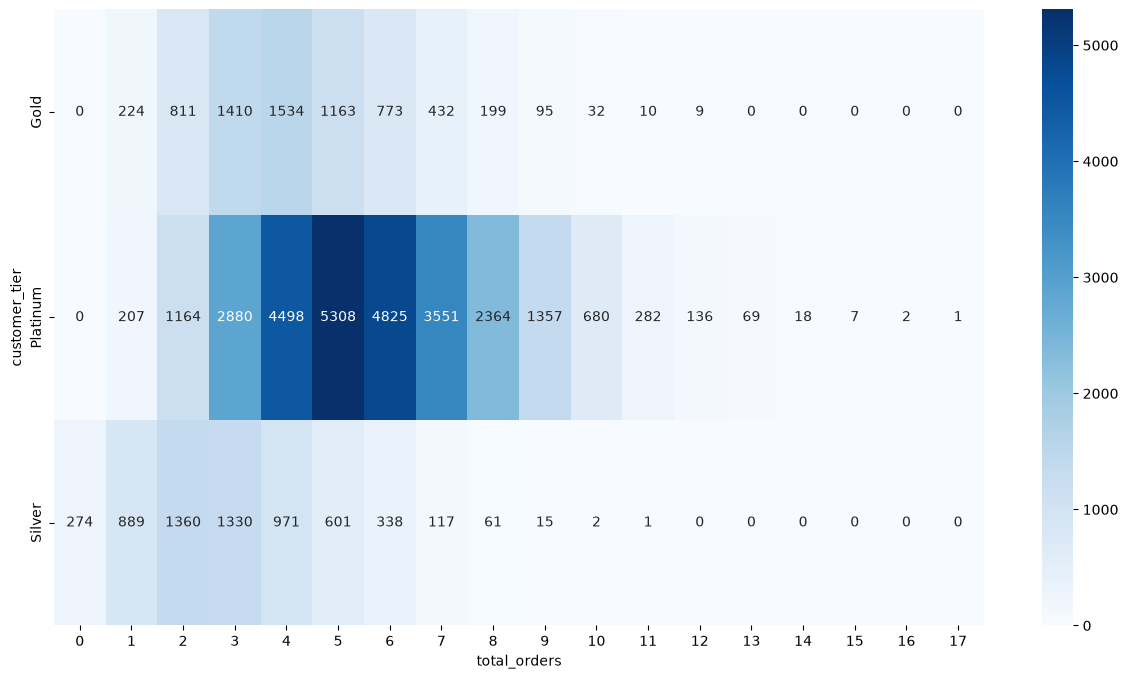

In [463]:
# customer tier and total orders
plt.figure(figsize=(15,8))
sns.heatmap(pd.crosstab(customers.customer_tier, customers.total_orders), annot=True, fmt='d', cmap='Blues')

* Silver Customers Skew Toward Fewer Orders
    * Peak volume for Silver sits at 2 and 3 orders
    * Order frequency for Silver drops sharply after 5 orders

* Gold Customers Peak in the Middle
    * The peak for Gold sits at 4 orders, closely followed by 3 orders
    * Gold represents a steady mid-frequency group, with counts trailing off above 7 orders and reaching zero past 12 orders

* Platinum
    * Platinum not only dominates total customer volume, but its peak shifts further to the right, centering at 5 orders and 6 orders
    * High-frequency activity is almost exclusively Platinum: beyond 10 orders, nearly all customers belong to the Platinum tier


* As customer tier moves from Silver $\rightarrow$ Gold $\rightarrow$ Platinum, the order count distribution shifts systematically to the right (Silver peaks at 2–3, Gold at 4, and Platinum at 5–6 orders)
* Any customer with 13 or more total orders is exclusively in the Platinum

<Axes: xlabel='customer_tier', ylabel='count'>

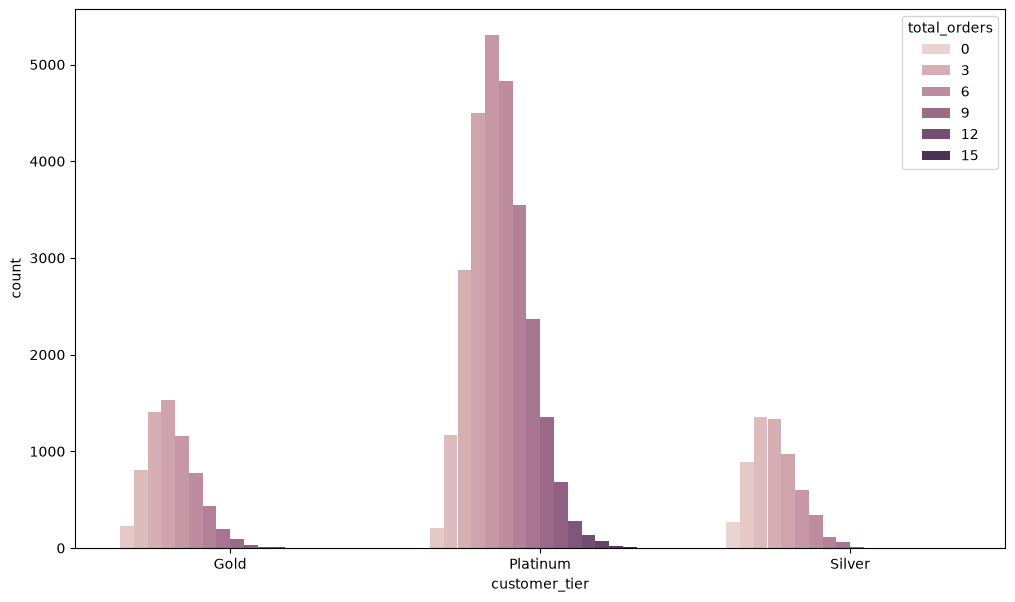

In [464]:
# customer tier and total orders
sns.countplot(data=customers, x="customer_tier", hue="total_orders")

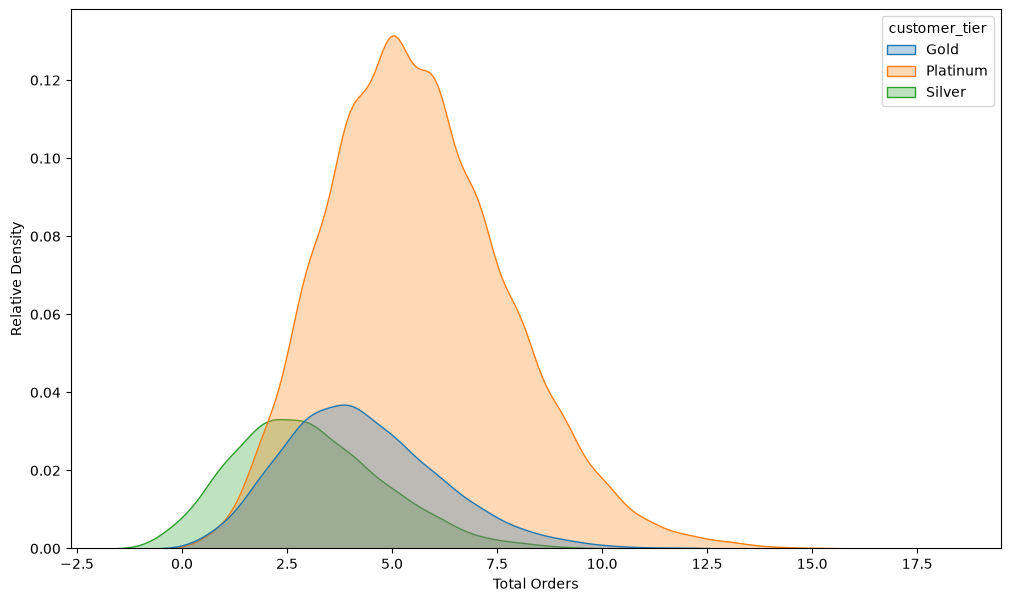

In [465]:
sns.kdeplot(
    data=customers,
    x="total_orders",
    hue="customer_tier",
    bw_adjust=1.8,
    fill=True,
    alpha=0.3,
)

plt.xlabel("Total Orders")
plt.ylabel("Relative Density")
plt.show()

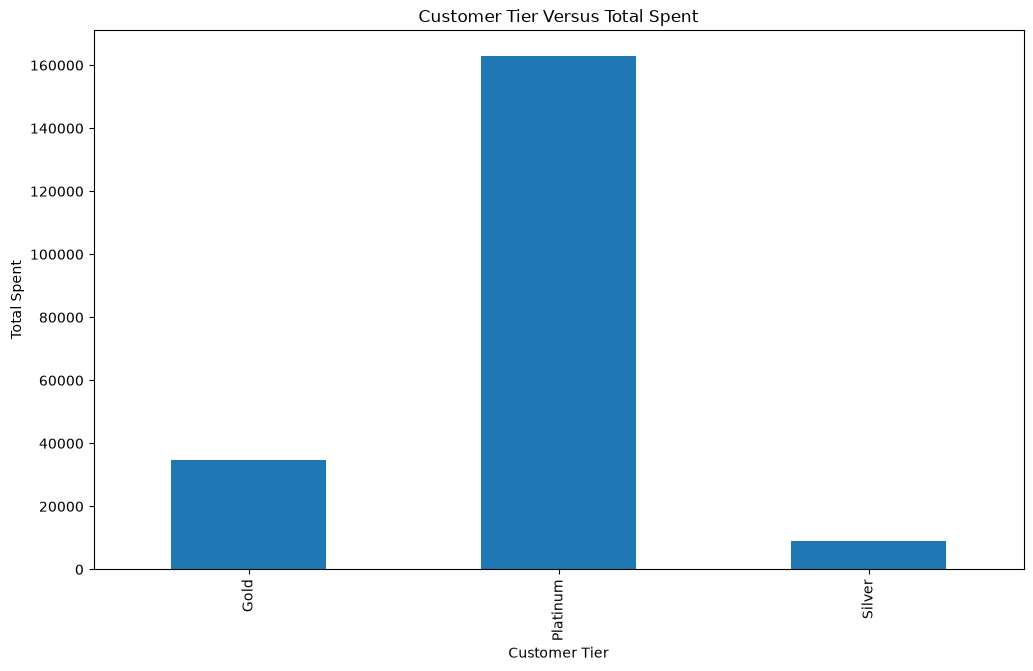

In [466]:
# customer tier and total spent
customers.groupby('customer_tier')['total_spent'].mean().plot(kind='bar')
plt.title("Customer Tier Versus Total Spent")
plt.xlabel("Customer Tier")
plt.ylabel("Total Spent")
plt.show()

* Average spending scales non-linearly with tier status: Silver (~9k) -> Gold (~35k) -> Platinum (~163k).
* Customer_tier is the underlying driver behind the spending collapse observed after age 45, as high-value Platinum members are predominantly younger.

In [467]:
df_merged = sales.merge(customers, on='customer_id', how='left')
df_merged = df_merged.merge(products, on='product_id', how='left')
df_merged.columns

Index(['order_id', 'customer_id', 'product_id', 'order_date', 'order_time',
       'delivery_date', 'quantity', 'unit_price', 'order_value',
       'shipping_cost', 'coupon_code', 'coupon_discount', 'total_amount',
       'payment_mode', 'order_status', 'rating', 'review_text',
       'customer_name', 'gender', 'age', 'email', 'city', 'state', 'pincode',
       'registration_date', 'customer_tier', 'total_orders', 'total_spent',
       'age_group', 'product_name', 'category', 'brand', 'original_price',
       'discount_percent', 'discount_amount', 'selling_price',
       'stock_quantity', 'weight_kg', 'avg_rating', 'total_reviews'],
      dtype='str')

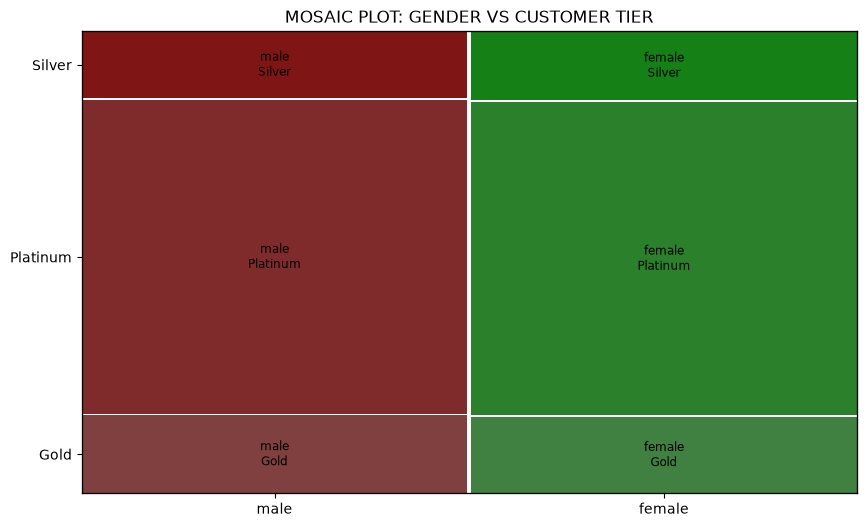

In [468]:
plt.rcParams['figure.figsize'] = (10, 6)
mosaic(customers, ['gender', 'customer_tier'], title='MOSAIC PLOT: GENDER VS CUSTOMER TIER')
plt.show()

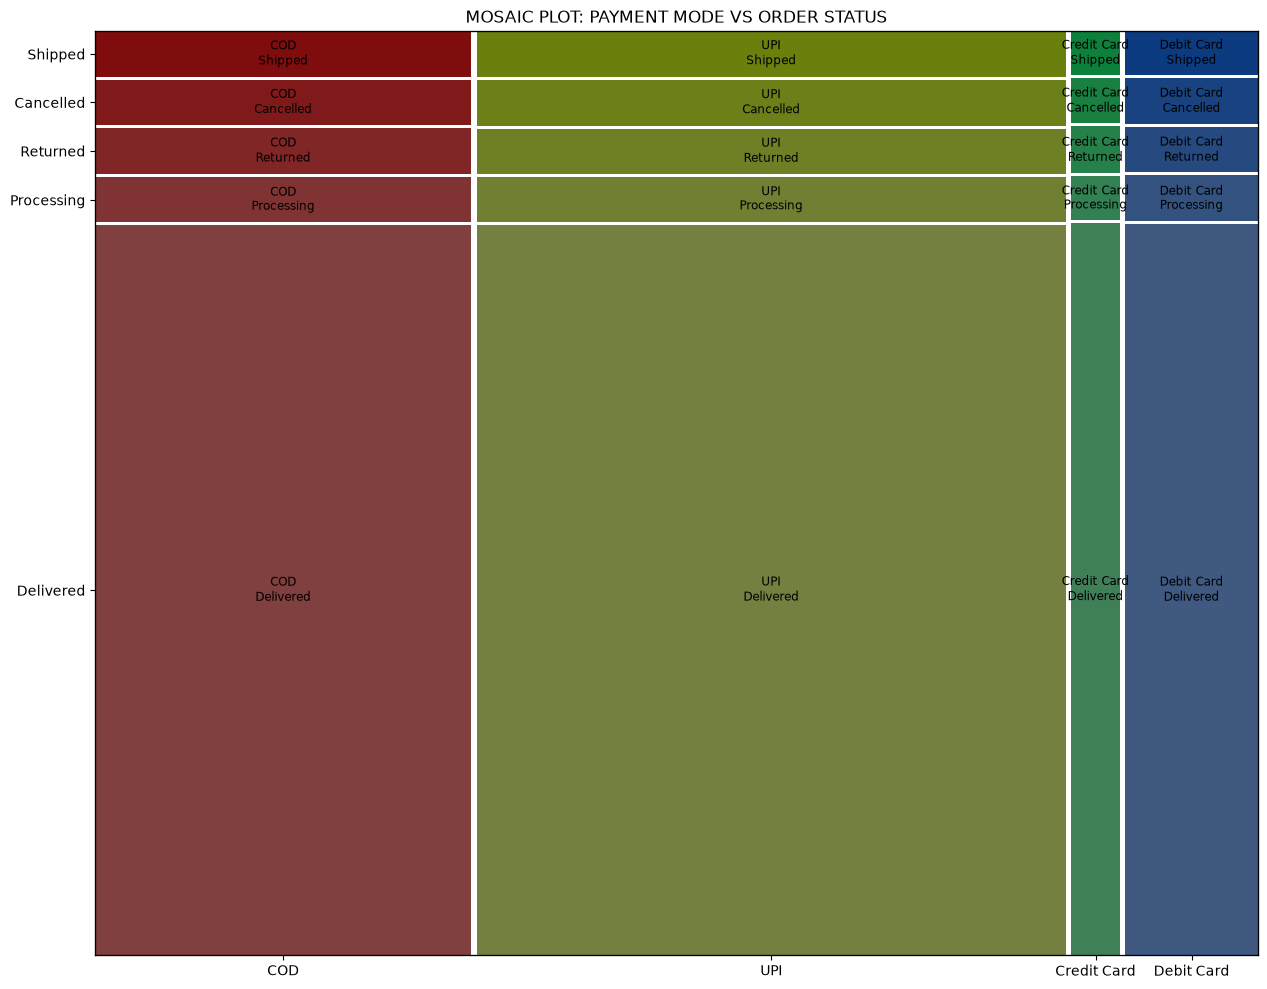

In [478]:
plt.rcParams['figure.figsize'] = (15, 12)
mosaic(sales, ['payment_mode', 'order_status'], title='MOSAIC PLOT: PAYMENT MODE VS ORDER STATUS')
plt.show()

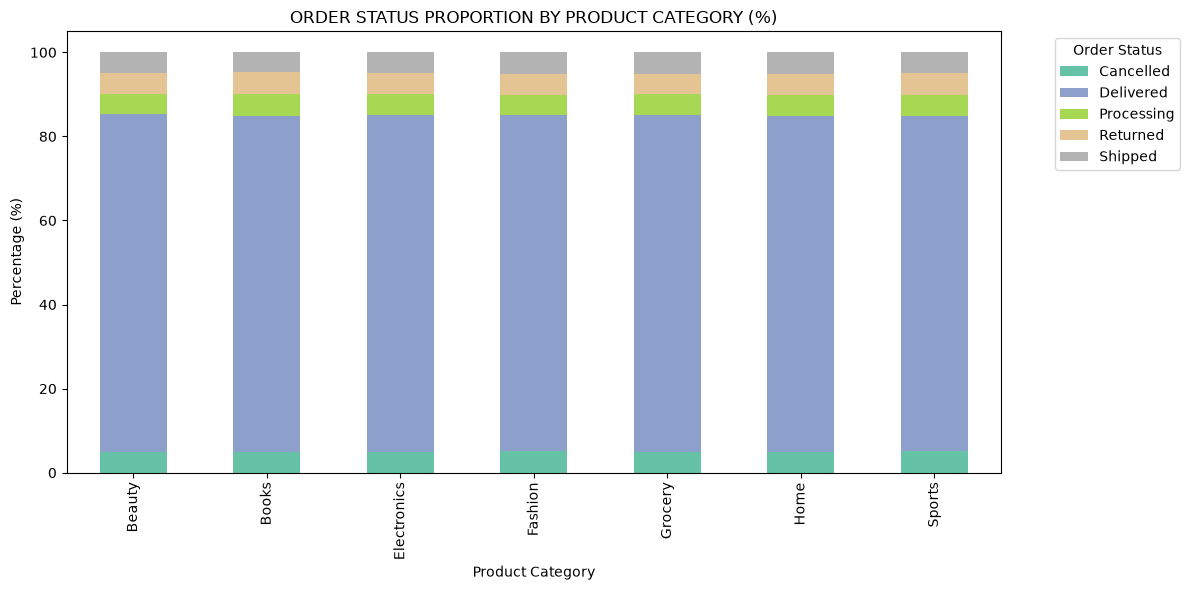

In [470]:
ct_cat_status = pd.crosstab(df_merged['category'], df_merged['order_status'], normalize='index') * 100
ct_cat_status.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='Set2')
plt.title("ORDER STATUS PROPORTION BY PRODUCT CATEGORY (%)")
plt.xlabel("Product Category")
plt.ylabel("Percentage (%)")
plt.legend(title='Order Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\tejas\AppData\Local\Temp\ipykernel_10340\2155996241.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customers, x='customer_tier', y='total_spent', order=['Silver', 'Gold', 'Platinum'], palette='pastel', ax=ax[0])
C:\Users\tejas\AppData\Local\Temp\ipykernel_10340\2155996241.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=customers, x='gender', y='total_spent', estimator=np.mean, palette=['skyblue', 'lightcoral'], ax=ax[1])


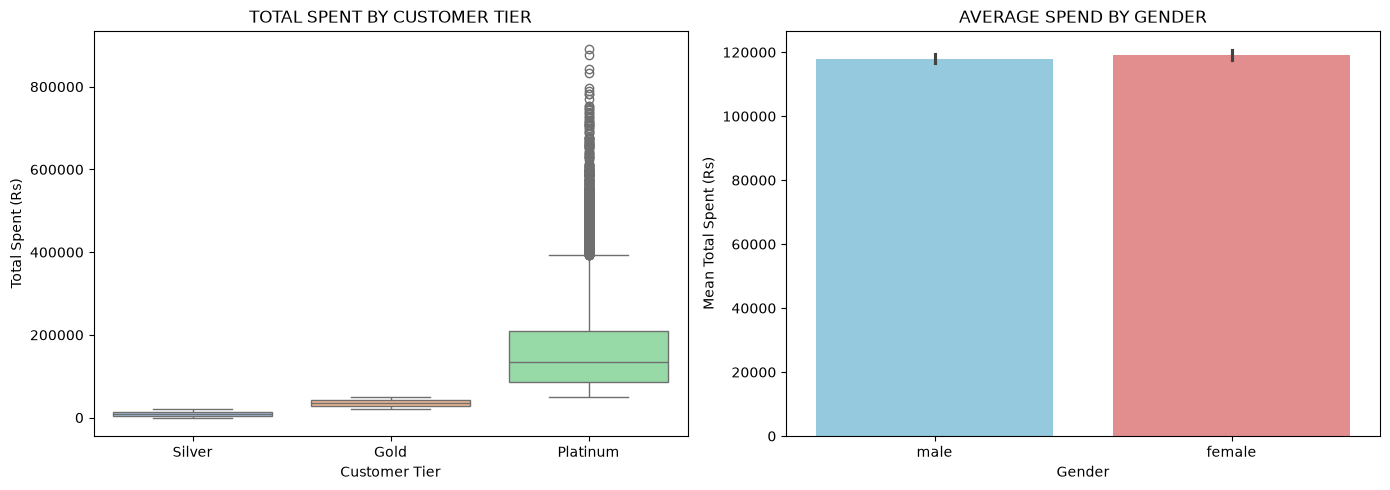

In [471]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.boxplot(data=customers, x='customer_tier', y='total_spent', order=['Silver', 'Gold', 'Platinum'], palette='pastel', ax=ax[0])
ax[0].set_title("TOTAL SPENT BY CUSTOMER TIER")
ax[0].set_xlabel("Customer Tier")
ax[0].set_ylabel("Total Spent (Rs)")

sns.barplot(data=customers, x='gender', y='total_spent', estimator=np.mean, palette=['skyblue', 'lightcoral'], ax=ax[1])
ax[1].set_title("AVERAGE SPEND BY GENDER")
ax[1].set_xlabel("Gender")
ax[1].set_ylabel("Mean Total Spent (Rs)")

plt.tight_layout()
plt.show()

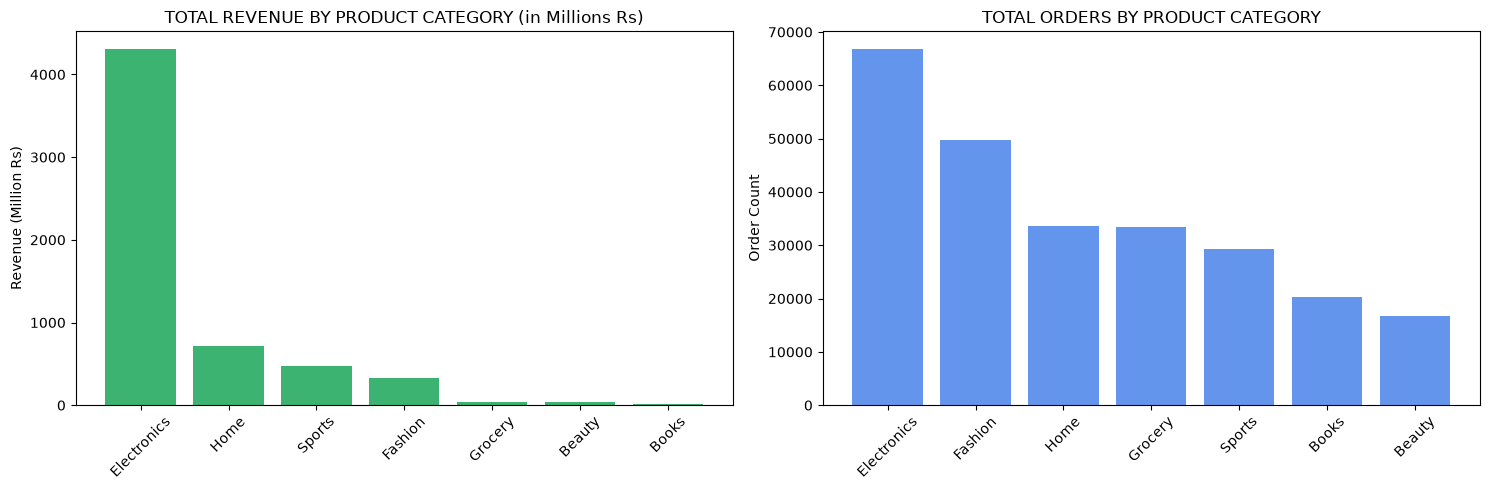

In [472]:
cat_revenue = df_merged.groupby('category')['total_amount'].sum().sort_values(ascending=False)
cat_orders = df_merged['category'].value_counts()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

ax[0].bar(cat_revenue.index, cat_revenue.values / 1e6, color='mediumseagreen')
ax[0].set_title("TOTAL REVENUE BY PRODUCT CATEGORY (in Millions Rs)")
ax[0].set_ylabel("Revenue (Million Rs)")
ax[0].tick_params(axis='x', rotation=45)

ax[1].bar(cat_orders.index, cat_orders.values, color='cornflowerblue')
ax[1].set_title("TOTAL ORDERS BY PRODUCT CATEGORY")
ax[1].set_ylabel("Order Count")
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

C:\Users\tejas\AppData\Local\Temp\ipykernel_10340\1006502155.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=state_revenue.index, y=state_revenue.values / 1e6, palette='viridis')


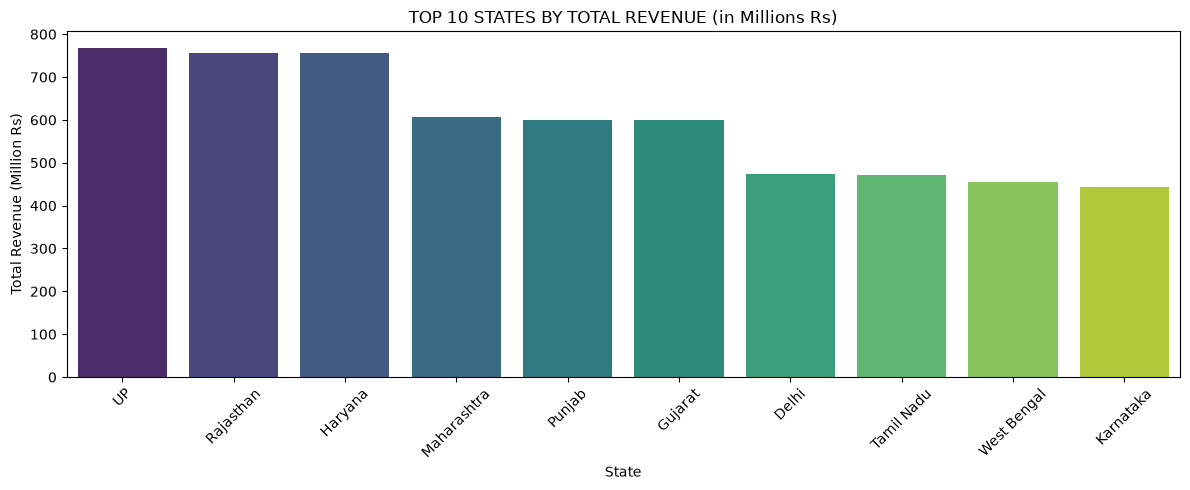

In [473]:
state_revenue = df_merged.groupby('state')['total_amount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=state_revenue.index, y=state_revenue.values / 1e6, palette='viridis')
plt.title("TOP 10 STATES BY TOTAL REVENUE (in Millions Rs)")
plt.xlabel("State")
plt.ylabel("Total Revenue (Million Rs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

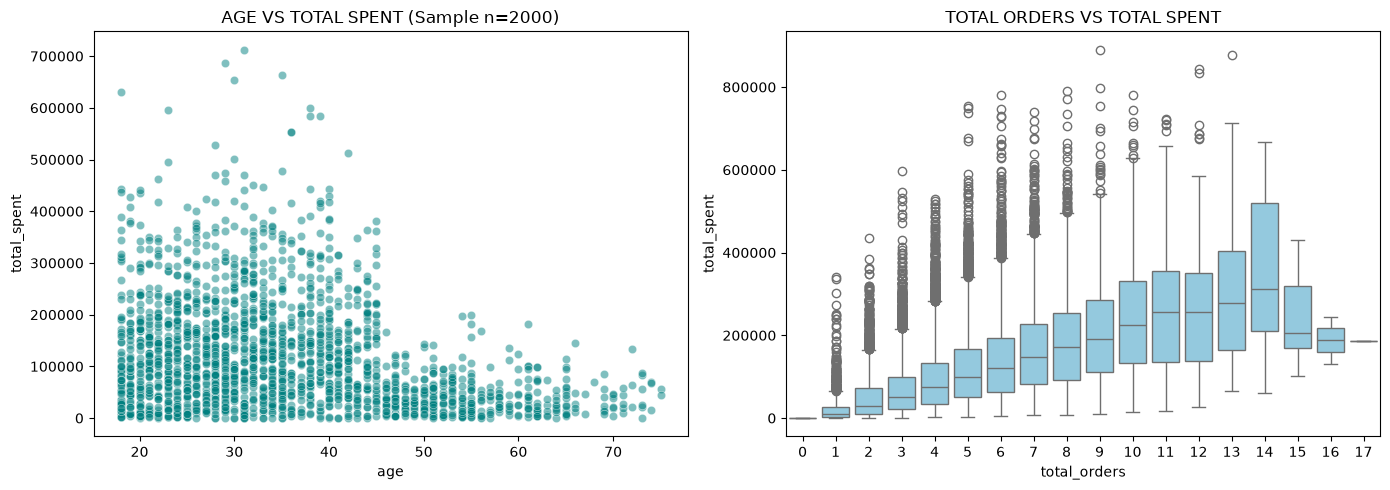

In [474]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.scatterplot(data=customers.sample(2000, random_state=42), x='age', y='total_spent', alpha=0.5, color='teal', ax=ax[0])
ax[0].set_title("AGE VS TOTAL SPENT (Sample n=2000)")

sns.boxplot(data=customers, x='total_orders', y='total_spent', color='skyblue', ax=ax[1])
ax[1].set_title("TOTAL ORDERS VS TOTAL SPENT")

plt.tight_layout()
plt.show()

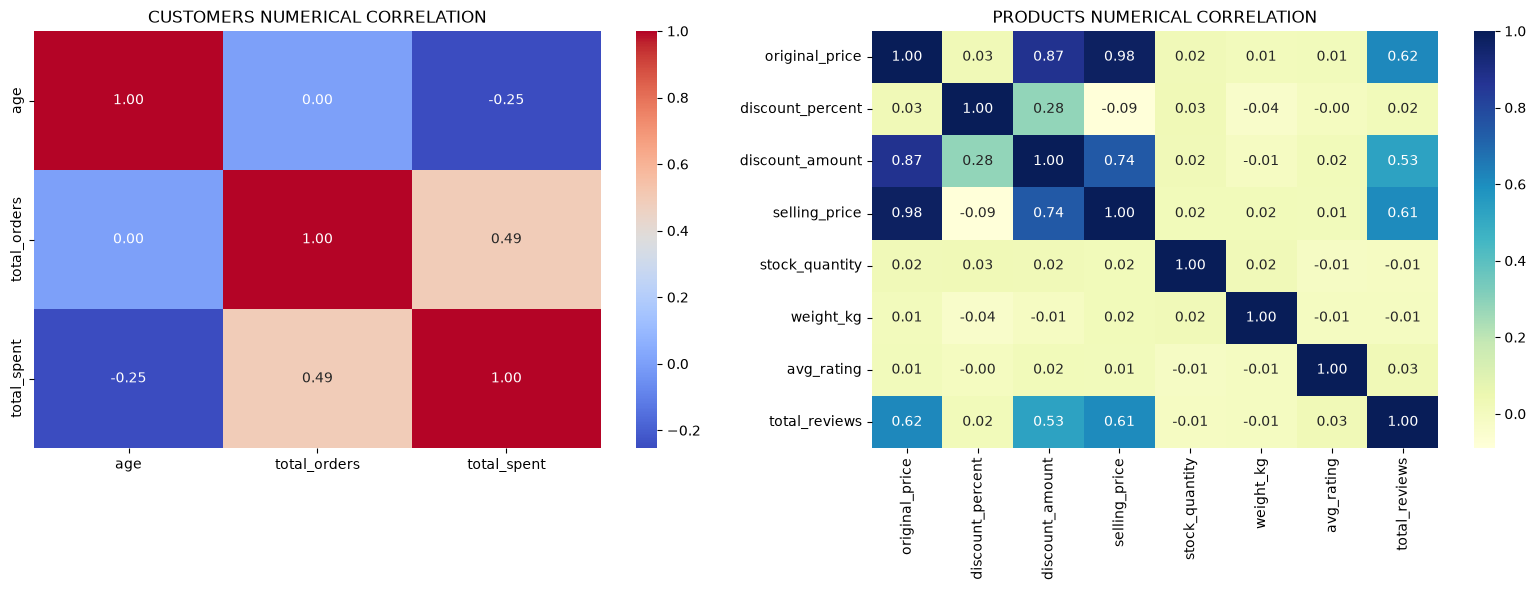

In [475]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

cust_corr = customers[['age', 'total_orders', 'total_spent']].corr()
sns.heatmap(cust_corr, annot=True, cmap='coolwarm', fmt='.2f', ax=ax[0])
ax[0].set_title("CUSTOMERS NUMERICAL CORRELATION")

prod_corr = products[['original_price', 'discount_percent', 'discount_amount', 'selling_price', 'stock_quantity', 'weight_kg', 'avg_rating', 'total_reviews']].corr()
sns.heatmap(prod_corr, annot=True, cmap='YlGnBu', fmt='.2f', ax=ax[1])
ax[1].set_title("PRODUCTS NUMERICAL CORRELATION")

plt.tight_layout()
plt.show()

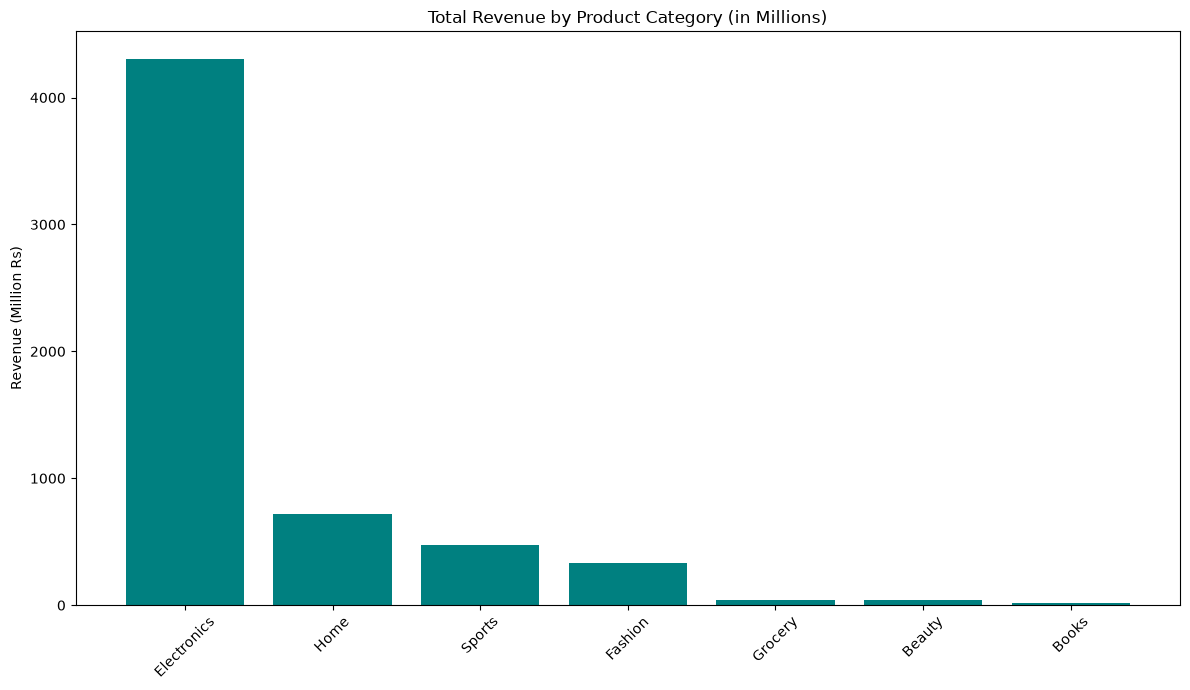

In [476]:
cat_rev = df_merged.groupby('category')['total_amount'].sum().sort_values(ascending=False)
plt.bar(cat_rev.index, cat_rev.values / 1e6, color='teal')
plt.title('Total Revenue by Product Category (in Millions)')
plt.ylabel('Revenue (Million Rs)')
plt.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()